# 🌊 Padma-Nariya River Erosion Detection — FINAL v7
## Single-Dataset Temporal Split Validation

**One path. One river. Two splits. Full research evaluation.**

| Split | Years | Images | Purpose |
|-------|-------|--------|---------|
| Training set | 2000–2022 | `IMG_PATH/*.tif` | Model operation + LOYO-CV |
| Test set | 2023–2025 | `IMG_PATH/*.tif` | Held-out temporal evaluation |

**All images come from one directory:** `/content/drive/MyDrive/Padma_new_v1/images`

**Evaluation outputs (research paper ready):**
- Precision · Recall · F1 per class (LOW / MEDIUM / HIGH)
- Macro F1 · Cohen's Kappa · Accuracy
- Confusion matrices (raw + normalised)
- Leave-One-Year-Out Cross-Validation (training set)
- Confidence calibration curve + Brier score
- Temporal erosion trend plots
- Train vs Test comparison bar chart
- Complete paper-ready metrics table

---
## PART 0 — Install & Imports

In [1]:
!pip install -q transformers==4.45.0 tokenizers==0.20.3 accelerate bitsandbytes \
    torchvision sentencepiece opencv-python-headless pandas matplotlib requests \
    rasterio scipy scikit-learn seaborn openpyxl

import os, cv2, json, re, torch, requests, warnings, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, cohen_kappa_score, classification_report,
    ConfusionMatrixDisplay, brier_score_loss, accuracy_score
)
from sklearn.calibration import calibration_curve
import rasterio
from tqdm import tqdm
warnings.filterwarnings('ignore')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE=='cuda' else 'CPU'
print(f'✅ Ready | device={DEVICE} | {GPU_NAME}')

^C


ModuleNotFoundError: No module named 'cv2'


[notice] A new release of pip is available: 26.0.1 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


---
## PART 1 — Configuration (edit only this cell)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# ════════════════════════════════════════════════════════════════════
#  ▶ ONLY CHANGE THESE TWO LINES IF YOUR PATHS ARE DIFFERENT
IMG_PATH = '/content/drive/MyDrive/Padma_new_v1/images'   # ALL Padma TIFs
OUT_PATH = '/content/drive/MyDrive/Padma_new_v1/output_v7'
# ════════════════════════════════════════════════════════════════════

# Year boundary for train / test split
TRAIN_END_YEAR = 2022   # images with year <= this → training
TEST_START_YEAR = 2023  # images with year >= this → test

# Padma river coordinates (for NASA POWER climate API)
LAT, LON = 23.33, 90.43

# Risk thresholds — calibrated from Islam et al. (2021) Remote Sensing
# and Sarker et al. (2014) for the Padma River monthly time scale
RISK_HIGH_KM2   = 2.0    # erosion_km² per monthly pair
RISK_MEDIUM_KM2 = 0.5
RISK_HIGH_SHIFT = 300    # channel centroid shift (metres)

# Processing constants
TILE_SIZE       = 256
CLOUD_THRESHOLD = 0.60   # skip image if >60% cloudy
MIN_WATER_PCT   = 0.01   # skip image if <1% water found

# Bangladesh monthly rainfall normals (mm) — BMD / WMO 1981-2010
# Source: Bangladesh Meteorological Department
BD_RAIN_NORMAL = {1:8,2:15,3:38,4:82,5:196,6:318,7:380,8:330,9:260,10:142,11:36,12:9}

MONTH_MAP  = {'jan':1,'feb':2,'mar':3,'apr':4,'may':5,'jun':6,
              'jul':7,'aug':8,'sep':9,'oct':10,'nov':11,'dec':12}
MONTH_ABBR = {v:k.capitalize() for k,v in MONTH_MAP.items()}
RISK_ORDER = ['LOW','MEDIUM','HIGH']
RISK_COLOR = {'HIGH':'#c0392b','MEDIUM':'#e67e22','LOW':'#27ae60','?':'#95a5a6'}

os.makedirs(OUT_PATH, exist_ok=True)
print(f'✅ Config ready')
print(f'  IMG_PATH : {IMG_PATH}')
print(f'  OUT_PATH : {OUT_PATH}')
print(f'  Train    : years <= {TRAIN_END_YEAR}')
print(f'  Test     : years >= {TEST_START_YEAR}')

Mounted at /content/drive
✅ Config ready
  IMG_PATH : /content/drive/MyDrive/Padma_new_v1/images
  OUT_PATH : /content/drive/MyDrive/Padma_new_v1/output_v7
  Train    : years <= 2022
  Test     : years >= 2023


---
## PART 2 — Image Preprocessing

In [ ]:
# Band layout for each Landsat version
BAND_CFG = {
    5:     {'R':3,'G':2,'B':1,'NIR':4,'SWIR1':5,'QA':None},
    7:     {'R':3,'G':2,'B':1,'NIR':4,'SWIR1':5,'QA':None},
    8:     {'R':4,'G':3,'B':2,'NIR':5,'SWIR1':6,'QA':7},
    9:     {'R':4,'G':3,'B':2,'NIR':5,'SWIR1':6,'QA':7},
    'gee': {'R':3,'G':2,'B':1,'NIR':4,'SWIR1':5,'QA':6},
}

# ── helpers ─────────────────────────────────────────────────────────────────
def detect_type(path):
    with rasterio.open(path) as s:
        n = s.count
    return 'SR_MULTIBAND' if n>=4 else ('RGB_EXPORT' if n==3 else 'GRAYSCALE')

def guess_ls(path, n):
    f = os.path.basename(path).lower()
    for v in [9,8,7,5]:
        if any(k in f for k in [f'lc0{v}',f'ls{v}',f'l{v}_']): return v
    return 'gee' if n==6 else (8 if n>=7 else 5)

def px_area_km2(src):
    rx,ry = src.res
    if src.crs and src.crs.is_projected:
        return abs(rx*ry)/1e6
    lat = (src.bounds.top+src.bounds.bottom)/2
    return abs(rx*111320*np.cos(np.radians(lat))*ry*111320)/1e6

def dos(arr):
    v = arr[arr>0]
    return np.maximum(arr.astype(np.float32)-(float(np.percentile(v,1)) if len(v) else 0),0)

def norm8(arr):
    lo,hi = np.nanpercentile(arr,2), np.nanpercentile(arr,98)
    if hi<=lo: return np.zeros_like(arr,dtype=np.uint8)
    return np.clip((arr-lo)/(hi-lo)*255,0,255).astype(np.uint8)

def cloud_bright(rgb):
    return (rgb[:,:,0]>210)&(rgb[:,:,1]>210)&(rgb[:,:,2]>210)

def water_index(rgb, bands, itype):
    """
    SR_MULTIBAND: true NDWI=(G-NIR)/(G+NIR) + mNDWI=(G-SWIR)/(G+SWIR), union
    RGB_EXPORT:   proxy mNDWI=(G-R)/(G+R) + blue dominance
    """
    if itype=='SR_MULTIBAND' and bands:
        g = bands['green'].astype(np.float32)
        n = bands['nir'].astype(np.float32)
        ndwi = (g-n)/(g+n+1e-8)
        s = bands.get('swir1')
        if s is not None:
            mndwi = (g-s.astype(np.float32))/(g+s.astype(np.float32)+1e-8)
            return np.clip(np.maximum(ndwi,mndwi),-1,1),'NDWI+mNDWI'
        return np.clip(ndwi,-1,1),'NDWI'
    r=rgb[:,:,0].astype(np.float32)
    g=rgb[:,:,1].astype(np.float32)
    b=rgb[:,:,2].astype(np.float32)
    return np.clip(0.6*(g-r)/(g+r+1e-8)+0.4*(b-r)/(b+r+1e-8),-1,1),'mNDWI_RGB'

def otsu_water(widx, cloud=None):
    """Otsu threshold on cloud-free pixels only + morphological cleanup."""
    idx8 = ((widx+1)/2*255).astype(np.uint8)
    if cloud is not None and cloud.any():
        vx = idx8[~cloud]
        if len(vx)<200: return np.zeros_like(idx8,dtype=bool),128.0
        h,_ = np.histogram(vx,bins=256,range=(0,256))
        T=h.sum(); St=np.dot(np.arange(256),h)
        sb=wb=bv=ov=0
        for t in range(256):
            wb+=h[t]
            if wb==0: continue
            wf=T-wb
            if wf==0: break
            sb+=t*h[t]; mb=sb/wb; mf=(St-sb)/wf
            v=wb*wf*(mb-mf)**2
            if v>bv: bv=v; ov=t
    else:
        ov,_=cv2.threshold(idx8,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    thr=min(float(ov),float(np.percentile(idx8,75)))
    m = idx8>thr
    if cloud is not None: m[cloud]=False
    k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(3,3))
    m8=m.astype(np.uint8)*255
    m8=cv2.morphologyEx(m8,cv2.MORPH_OPEN, k,iterations=1)
    m8=cv2.morphologyEx(m8,cv2.MORPH_CLOSE,k,iterations=2)
    return m8>0, thr

# ── main preprocessing function ──────────────────────────────────────────────
def preprocess(path, label, debug=False):
    try:
        itype = detect_type(path)
        if itype=='GRAYSCALE':
            if debug: print(f'  [{label}] GRAYSCALE — excluded')
            return None

        with rasterio.open(path) as src:
            pxkm2 = px_area_km2(src)
            n = src.count
            bands = None

            if itype=='SR_MULTIBAND':
                lv = guess_ls(path,n); cfg=BAND_CFG[lv]
                def rb(i): return src.read(i).astype(np.float32) if i and i<=n else None
                gr=rb(cfg['G']); rr=rb(cfg['R']) or gr
                br=rb(cfg['B']) or gr; nr=rb(cfg['NIR']) or gr
                sr=rb(cfg['SWIR1']); qr=rb(cfg['QA'])
                g=dos(gr); r=dos(rr); b=dos(br); nir=dos(nr)
                sw=dos(sr) if sr is not None else None
                rgb=np.stack([norm8(r),norm8(g),norm8(b)],axis=-1)
                if qr is not None:
                    q=qr.astype(np.uint16)
                    cloud=((q>>3)&1).astype(bool)|((q>>4)&1).astype(bool)
                else:
                    cloud=cloud_bright(rgb)
                bands={'green':g,'nir':nir,'swir1':sw}
            else:
                r_=src.read(1).astype(np.float32)
                g_=src.read(2).astype(np.float32)
                b_=src.read(3).astype(np.float32)
                rgb=np.stack([norm8(r_),norm8(g_),norm8(b_)],axis=-1)
                cloud=cloud_bright(rgb)

        cld_pct=float(cloud.mean())
        # Inpaint clouds
        cm8=(cloud*255).astype(np.uint8)
        for c in range(3):
            rgb[:,:,c]=cv2.inpaint(rgb[:,:,c],cm8,5,cv2.INPAINT_TELEA)
        # Water index (full res)
        widx,ilbl=water_index(rgb,bands,itype)
        widx[cloud]=widx[~cloud].mean() if (~cloud).any() else 0.0
        # Resize
        rgb256 =cv2.resize(rgb,  (TILE_SIZE,TILE_SIZE),interpolation=cv2.INTER_LANCZOS4)
        widx256=cv2.resize(widx, (TILE_SIZE,TILE_SIZE),interpolation=cv2.INTER_LINEAR)
        cm256  =cv2.resize(cloud.astype(np.uint8),(TILE_SIZE,TILE_SIZE),
                           interpolation=cv2.INTER_NEAREST).astype(bool)
        wm,othr=otsu_water(widx256,cm256)
        wpct=float(wm.mean())
        valid=(cld_pct<=CLOUD_THRESHOLD)and(wpct>MIN_WATER_PCT)

        if debug:
            print(f'  [{label}] {itype} | {ilbl} | '
                  f'cloud={cld_pct:.1%} water={wpct:.1%} '
                  f'px={pxkm2*1e6:.0f}m² valid={valid}')
        return {'rgb':rgb256,'water_mask':wm,'water_index':widx256,
                'cloud_mask':cm256,'cloud_pct':round(cld_pct,3),
                'water_pct':round(wpct,3),'threshold':round(othr,1),
                'px_km2':pxkm2,'valid':valid,
                'itype':itype,'ilabel':ilbl}
    except Exception as e:
        print(f'  ❌ [{label}]: {e}'); return None

print('✅ Preprocessing ready')

✅ Preprocessing ready


---
## PART 3 — Change Detection & Geomorphic Metrics

In [ ]:
def change_detect(p0,p1):
    m0,m1   = p0['water_mask'],p1['water_mask']
    c0,c1   = p0['cloud_mask'],p1['cloud_mask']
    valid   = (~c0)&(~c1)
    erosion = valid&(~m0)&m1    # land→water: bank eroded
    deposit = valid&m0&(~m1)    # water→land: sediment
    return erosion,deposit,m0,m1,valid

def geomorphic_metrics(er,dep,m0,m1,valid,pxkm2):
    def A(mask): return float(np.sum(mask))*pxkm2
    er_km2=A(er); dep_km2=A(dep); net=er_km2-dep_km2
    w0=A(m0&valid); w1=A(m1&valid)
    y0,x0=np.where(m0&valid); y1,x1=np.where(m1&valid)
    px_m=float(np.sqrt(pxkm2*1e6))
    if len(x0)>0 and len(x1)>0:
        dx=float(np.mean(x1)-np.mean(x0)); dy=float(np.mean(y1)-np.mean(y0))
        shift_m=np.sqrt(dx**2+dy**2)*px_m
        sdir=('E' if dx>0 else 'W')+('S' if dy>0 else 'N')
    else:
        dx=dy=shift_m=0.; sdir='none'
    wchg=(float(np.mean(np.sum(m1,axis=1))-np.mean(np.sum(m0,axis=1))))*px_m
    cr=net/(w0+1e-9)
    return {'erosion_km2':round(er_km2,4),'deposit_km2':round(dep_km2,4),
            'net_km2':round(net,4),'change_ratio':round(cr,4),
            'water_t0_km2':round(w0,4),'water_t1_km2':round(w1,4),
            'shift_m':round(shift_m,1),'shift_dir':sdir,
            'width_chg_m':round(wchg,1),'valid_pct':round(float(valid.mean()),3),
            'px_km2':pxkm2}

print('✅ Change detection ready')

✅ Change detection ready


---
## PART 4 — Climate Data & SPI Drought Index

In [ ]:
def fetch_climate(lat,lon,start,end):
    """NASA POWER API — rainfall, soil moisture, temperature."""
    url='https://power.larc.nasa.gov/api/temporal/daily/point'
    p={'parameters':'PRECTOTCORR,GWETROOT,T2M','community':'AG',
       'longitude':lon,'latitude':lat,'start':start,'end':end,'format':'JSON'}
    try:
        r=requests.get(url,params=p,timeout=30); r.raise_for_status()
        d=r.json()['properties']['parameter']
        rain=[v for v in d['PRECTOTCORR'].values() if v!=-999] or [0]
        soil=[v for v in d['GWETROOT'].values()    if v!=-999] or [0.5]
        temp=[v for v in d['T2M'].values()         if v!=-999] or [25]
        return {'rain_total':round(float(np.sum(rain)),1),
                'rain_max':  round(float(np.max(rain)),1),
                'rain_days': int(np.sum(np.array(rain)>1.0)),
                'soil':      round(float(np.mean(soil)),3),
                'temp_c':    round(float(np.mean(temp)),1)}
    except Exception as e:
        print(f'  NASA API: {e}')
        return {'rain_total':0,'rain_max':0,'rain_days':0,'soil':0.5,'temp_c':25}

def spi(env,month):
    """
    SPI-proxy drought index using BMD monthly normals.
    Returns (drought_idx, drought_level, normal_mm)
    Positive = drier than normal; 0 = at/above normal.
    """
    nm=BD_RAIN_NORMAL.get(int(month),100)
    rf=max(0.0,1.0-env['rain_total']/(nm+1e-9))
    sf=max(0.0,1.0-env['soil'])
    idx=round(rf*0.6+sf*0.4,3)
    lvl=('EXTREME_DROUGHT' if idx>0.70 else
         'MODERATE_DROUGHT' if idx>0.50 else
         'MILD_DROUGHT'     if idx>0.30 else
         'WET'              if idx<0.10 else 'NORMAL')
    return idx,lvl,nm

print('✅ Climate / SPI functions ready')

✅ Climate / SPI functions ready


---
## PART 5 — Rule-Based Reference Labels (Pseudo-Ground Truth)

In [ ]:
def rule_label(m):
    """
    Pseudo-ground-truth using literature-calibrated thresholds.
    Reference: Islam et al. (2021) Remote Sensing — Padma River monthly erosion.
    Returns (risk_level, base_confidence)
    """
    if m['erosion_km2']>RISK_HIGH_KM2 or m['shift_m']>RISK_HIGH_SHIFT:
        return 'HIGH',  0.85
    elif m['erosion_km2']>RISK_MEDIUM_KM2:
        return 'MEDIUM',0.75
    else:
        return 'LOW',   0.65

print('✅ Rule-based labels ready')

✅ Rule-based labels ready


---
## PART 6 — Load Qwen2-VL-2B Model

In [ ]:
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig

bnb=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_compute_dtype=torch.float16,
                       bnb_4bit_use_double_quant=True,bnb_4bit_quant_type='nf4')
model=Qwen2VLForConditionalGeneration.from_pretrained(
    'Qwen/Qwen2-VL-2B-Instruct',quantization_config=bnb,device_map='auto')
model.eval()
processor=AutoProcessor.from_pretrained('Qwen/Qwen2-VL-2B-Instruct')
print(f'✅ Qwen2-VL-2B-Instruct loaded | '
      f'VRAM: {torch.cuda.memory_allocated()/1e9:.2f} GB')

config.json: 0.00B [00:00, ?B/s]

Unrecognized keys in `rope_scaling` for 'rope_type'='default': {'mrope_section'}


model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/3.99G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/429M [00:00<?, ?B/s]

`Qwen2VLRotaryEmbedding` can now be fully parameterized by passing the model config through the `config` argument. All other arguments will be removed in v4.46


... (5 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

✅ Qwen2-VL-2B-Instruct loaded | VRAM: 1.52 GB


---
## PART 7 — VLM Prompt Engineering & Inference

In [ ]:
# ── System message: strict JSON instruction, no schema placeholder ───────────
SYSTEM_MSG = """You are a senior river geomorphologist specialising in delta erosion dynamics.
You will see two satellite images side by side (LEFT=t0 before, RIGHT=t1 after)
and structured geomorphic + climate measurements.

Step 1: Briefly state what you observe in the images (1-2 sentences).
Step 2: Output a single JSON object with these exact keys:
  risk_level        — must be exactly: HIGH, MEDIUM, or LOW
  confidence        — float 0.0 to 1.0
  erosion_evidence  — what you see in the images supporting erosion/stability
  channel_evidence  — channel shift, width change, or planform change observed
  cause             — primary physical driver of the observed change
  forecast          — 1-sentence prediction for the next 12 months

Output only the JSON object after your observation. No markdown code fences."""

# ── Few-shot: one complete filled example (real values, not schema) ───────────
FEW_SHOT = """Example — correct output format:
The left image shows a broad active channel. The right image shows clear left-bank retreat with
newly exposed sand bars and turbid water where land previously existed.
{"risk_level":"HIGH","confidence":0.87,"erosion_evidence":"Left bank receded ~380m; new sand
exposure visible at north margin; water area expanded into cultivated land.",
"channel_evidence":"Centroid shifted 540m eastward; main thread narrowed on west side by ~120m.",
"cause":"Pre-monsoon discharge pulse combined with unconsolidated silt left bank.",
"forecast":"Continued high erosion risk through monsoon season; expect further 200-400m eastward
migration over next 12 months."}
"""

def build_prompt(m,env,d_idx,d_lvl,nm,t0,t1):
    rpct=f'{env["rain_total"]/(nm+1e-9)*100:.0f}% of monthly normal'
    return (FEW_SHOT +
f"""Now analyze: LEFT={t0.upper()} | RIGHT={t1.upper()} | River=Padma-Nariya, Bangladesh

GEOMORPHIC MEASUREMENTS:
  erosion_area   = {m['erosion_km2']:.4f} km²   (land that became water)
  deposition     = {m['deposit_km2']:.4f} km²   (water that became land)
  net_change     = {m['net_km2']:.4f} km²  ({'net land loss' if m['net_km2']>=0 else 'net land gain'})
  change_ratio   = {m['change_ratio']:.3f}  (net/initial water area)
  channel_shift  = {m['shift_m']:.1f} m toward {m['shift_dir']}
  width_change   = {m['width_chg_m']:.1f} m  ({'widened' if m['width_chg_m']>0 else 'narrowed'})
  initial_water  = {m['water_t0_km2']:.3f} km²
  final_water    = {m['water_t1_km2']:.3f} km²
  valid_pixels   = {m['valid_pct']:.1%} (cloud-free)

CLIMATE — SPI DROUGHT INDEX:
  rainfall_total = {env['rain_total']} mm  ({rpct})
  rainfall_max   = {env['rain_max']} mm/day
  rain_days      = {env['rain_days']}
  soil_moisture  = {env['soil']:.3f}
  temp_mean      = {env['temp_c']} °C
  drought_index  = {d_idx}  ({d_lvl})

RISK THRESHOLDS (Islam et al. 2021, Padma monthly scale):
  HIGH   = erosion > {RISK_HIGH_KM2} km²  OR  shift > {RISK_HIGH_SHIFT} m
  MEDIUM = erosion {RISK_MEDIUM_KM2}–{RISK_HIGH_KM2} km²
  LOW    = erosion < {RISK_MEDIUM_KM2} km²
""")

def fused_image(rgb0,rgb1):
    div=np.full((TILE_SIZE,4,3),160,dtype=np.uint8)
    return Image.fromarray(np.hstack([rgb0,div,rgb1]))

def run_vlm(rgb0,rgb1,prompt,max_tok=512):
    fused=fused_image(rgb0,rgb1)
    msgs=[{'role':'system','content':[{'type':'text','text':SYSTEM_MSG}]},
          {'role':'user','content':[{'type':'image','image':fused},
                                    {'type':'text','text':prompt}]}]
    try:
        ti=processor.apply_chat_template(msgs,tokenize=False,add_generation_prompt=True)
        inp=processor(text=[ti],images=[fused],return_tensors='pt',padding=True).to(model.device)
    except:
        inp=processor(text=[SYSTEM_MSG+'\n'+prompt],images=[fused],
                      return_tensors='pt',padding=True).to(model.device)
    ilen=inp['input_ids'].shape[1]
    with torch.no_grad():
        out=model.generate(**inp,max_new_tokens=max_tok,do_sample=False,
                           temperature=None,top_p=None,top_k=None,
                           repetition_penalty=1.1,
                           pad_token_id=processor.tokenizer.eos_token_id)
    resp=processor.decode(out[0][ilen:],skip_special_tokens=True).strip()
    torch.cuda.empty_cache()
    return resp

def parse_vlm(text):
    """5-strategy robust JSON extraction. Rejects schema-echo placeholders."""
    text=re.sub(r'```json|```','',text).strip()
    def fix(s):
        s=re.sub(r"(?<![\w])'([^']*)'(?![\w])",r'"\1"',s)
        return re.sub(r',\s*([}\]])',r'\1',s)
    req={'risk_level','confidence'}
    for fn in [
        lambda t: json.loads(t),
        lambda t: json.loads(fix(t)),
        lambda t: json.loads(fix(re.search(r'\{[^{}]+\}',t,re.DOTALL).group())),
        lambda t: json.loads(fix(re.findall(r'\{[^{}]+\}',t,re.DOTALL)[-1])),
        lambda t: json.loads(fix(max(re.findall(r'\{.*?\}',t,re.DOTALL),key=len))),
    ]:
        try:
            r=fn(text)
            if isinstance(r,dict) and req.issubset(r.keys()):
                rl=str(r.get('risk_level',''))
                if rl in ('HIGH','MEDIUM','LOW') and '|' not in rl:
                    return r,'vlm_parsed'
        except: pass
    return None,'parse_failed'

print('✅ VLM inference ready')

✅ VLM inference ready


---
## PART 8 — Load All Images & Split Train / Test

In [ ]:
def load_dataset(img_dir):
    """
    Scan IMG_PATH for all TIFs with names like '2000_jan.tif' or '2023_apr.tif'.
    Returns list of dicts sorted by (year, month).
    """
    data=[]
    if not os.path.isdir(img_dir):
        print(f'  ❌ Not found: {img_dir}'); return data
    for f in sorted(os.listdir(img_dir)):
        if not f.lower().endswith('.tif'): continue
        try:
            base=f.lower().replace('.tif','')
            parts=base.split('_')
            yr_p=next(p for p in parts if p.isdigit() and len(p)==4)
            mo_p=next((p for p in parts if p in MONTH_MAP),None)
            if mo_p is None:
                # try 2-digit month number
                mn=next((int(p) for p in parts
                         if p.isdigit() and 1<=int(p)<=12 and p!=yr_p),None)
            else:
                mn=MONTH_MAP[mo_p]
            if mn is None: continue
            yr=int(yr_p)
            data.append({'year':yr,'month':mn,
                         'path':os.path.join(img_dir,f),
                         'label':f'{yr}_{MONTH_ABBR.get(mn,str(mn))}'})
        except: continue
    data=sorted(data,key=lambda x:(x['year'],x['month']))
    return data

def consecutive_pairs(dataset,cache):
    pairs=[]
    for i in range(len(dataset)-1):
        t0,t1=dataset[i],dataset[i+1]
        # Only consecutive months (gap==1)
        if t1['year']*12+t1['month']-t0['year']*12-t0['month']==1:
            if t0['label'] in cache and t1['label'] in cache:
                pairs.append((t0,t1))
    return pairs

def preprocess_all(dataset,tag,debug_n=3):
    cache,skip={},{}
    for i,e in enumerate(tqdm(dataset,desc=f'Preprocessing {tag}')):
        res=preprocess(e['path'],e['label'],debug=(i<debug_n))
        if res is None:
            skip[e['label']]='grayscale/error'
        elif not res['valid']:
            skip[e['label']]='cloudy' if res['cloud_pct']>CLOUD_THRESHOLD else 'no_water'
        else:
            cache[e['label']]=res
    print(f'  {tag}: valid={len(cache)}  skipped={len(skip)}')
    return cache

# ── Load ALL images from one path ────────────────────────────────────────────
print('📂 Loading all TIFs from IMG_PATH...')
all_imgs = load_dataset(IMG_PATH)
print(f'  Total images found: {len(all_imgs)}')
if all_imgs:
    years_found=sorted(set(x['year'] for x in all_imgs))
    print(f'  Year range: {years_found[0]} – {years_found[-1]}')

# ── Split by year ─────────────────────────────────────────────────────────────
train_imgs = [x for x in all_imgs if x['year'] <= TRAIN_END_YEAR]
test_imgs  = [x for x in all_imgs if x['year'] >= TEST_START_YEAR]

print(f'\n  Train images (≤{TRAIN_END_YEAR}): {len(train_imgs)}')
print(f'  Test  images (≥{TEST_START_YEAR}): {len(test_imgs)}')

# ── Preprocess both splits ────────────────────────────────────────────────────
print('\n⏳ Preprocessing training set...')
cache_train = preprocess_all(train_imgs,'TRAIN')

print('\n⏳ Preprocessing test set...')
cache_test  = preprocess_all(test_imgs,'TEST')

# ── Build consecutive pairs ───────────────────────────────────────────────────
pairs_train = consecutive_pairs(train_imgs, cache_train)
pairs_test  = consecutive_pairs(test_imgs,  cache_test)

print(f'\n✅ Train pairs: {len(pairs_train)}')
print(f'✅ Test  pairs: {len(pairs_test)}')

📂 Loading all TIFs from IMG_PATH...
  Total images found: 208
  Year range: 2000 – 2025

  Train images (≤2022): 184
  Test  images (≥2023): 24

⏳ Preprocessing training set...


Preprocessing TRAIN:   1%|          | 1/184 [00:01<03:40,  1.21s/it]

  [2000_Jan] RGB_EXPORT | mNDWI_RGB | cloud=9.9% water=19.9% px=826m² valid=True


Preprocessing TRAIN:   1%|          | 2/184 [00:01<02:55,  1.04it/s]

  [2000_Feb] RGB_EXPORT | mNDWI_RGB | cloud=3.9% water=23.2% px=826m² valid=True


Preprocessing TRAIN:   2%|▏         | 3/184 [00:05<06:39,  2.21s/it]

... (3 outputs left out)

Preprocessing TEST:   8%|▊         | 2/24 [00:00<00:01, 12.54it/s]

  [2023_Jan] RGB_EXPORT | mNDWI_RGB | cloud=5.0% water=22.0% px=826m² valid=True
  [2023_Feb] RGB_EXPORT | mNDWI_RGB | cloud=3.1% water=32.1% px=826m² valid=True
  [2023_Mar] RGB_EXPORT | mNDWI_RGB | cloud=4.6% water=45.3% px=826m² valid=True


Preprocessing TEST: 100%|██████████| 24/24 [00:03<00:00,  6.25it/s]

  TEST: valid=23  skipped=1

✅ Train pairs: 127
✅ Test  pairs: 19


---
## PART 9 — Sanity Check: Water Mask Visual QA

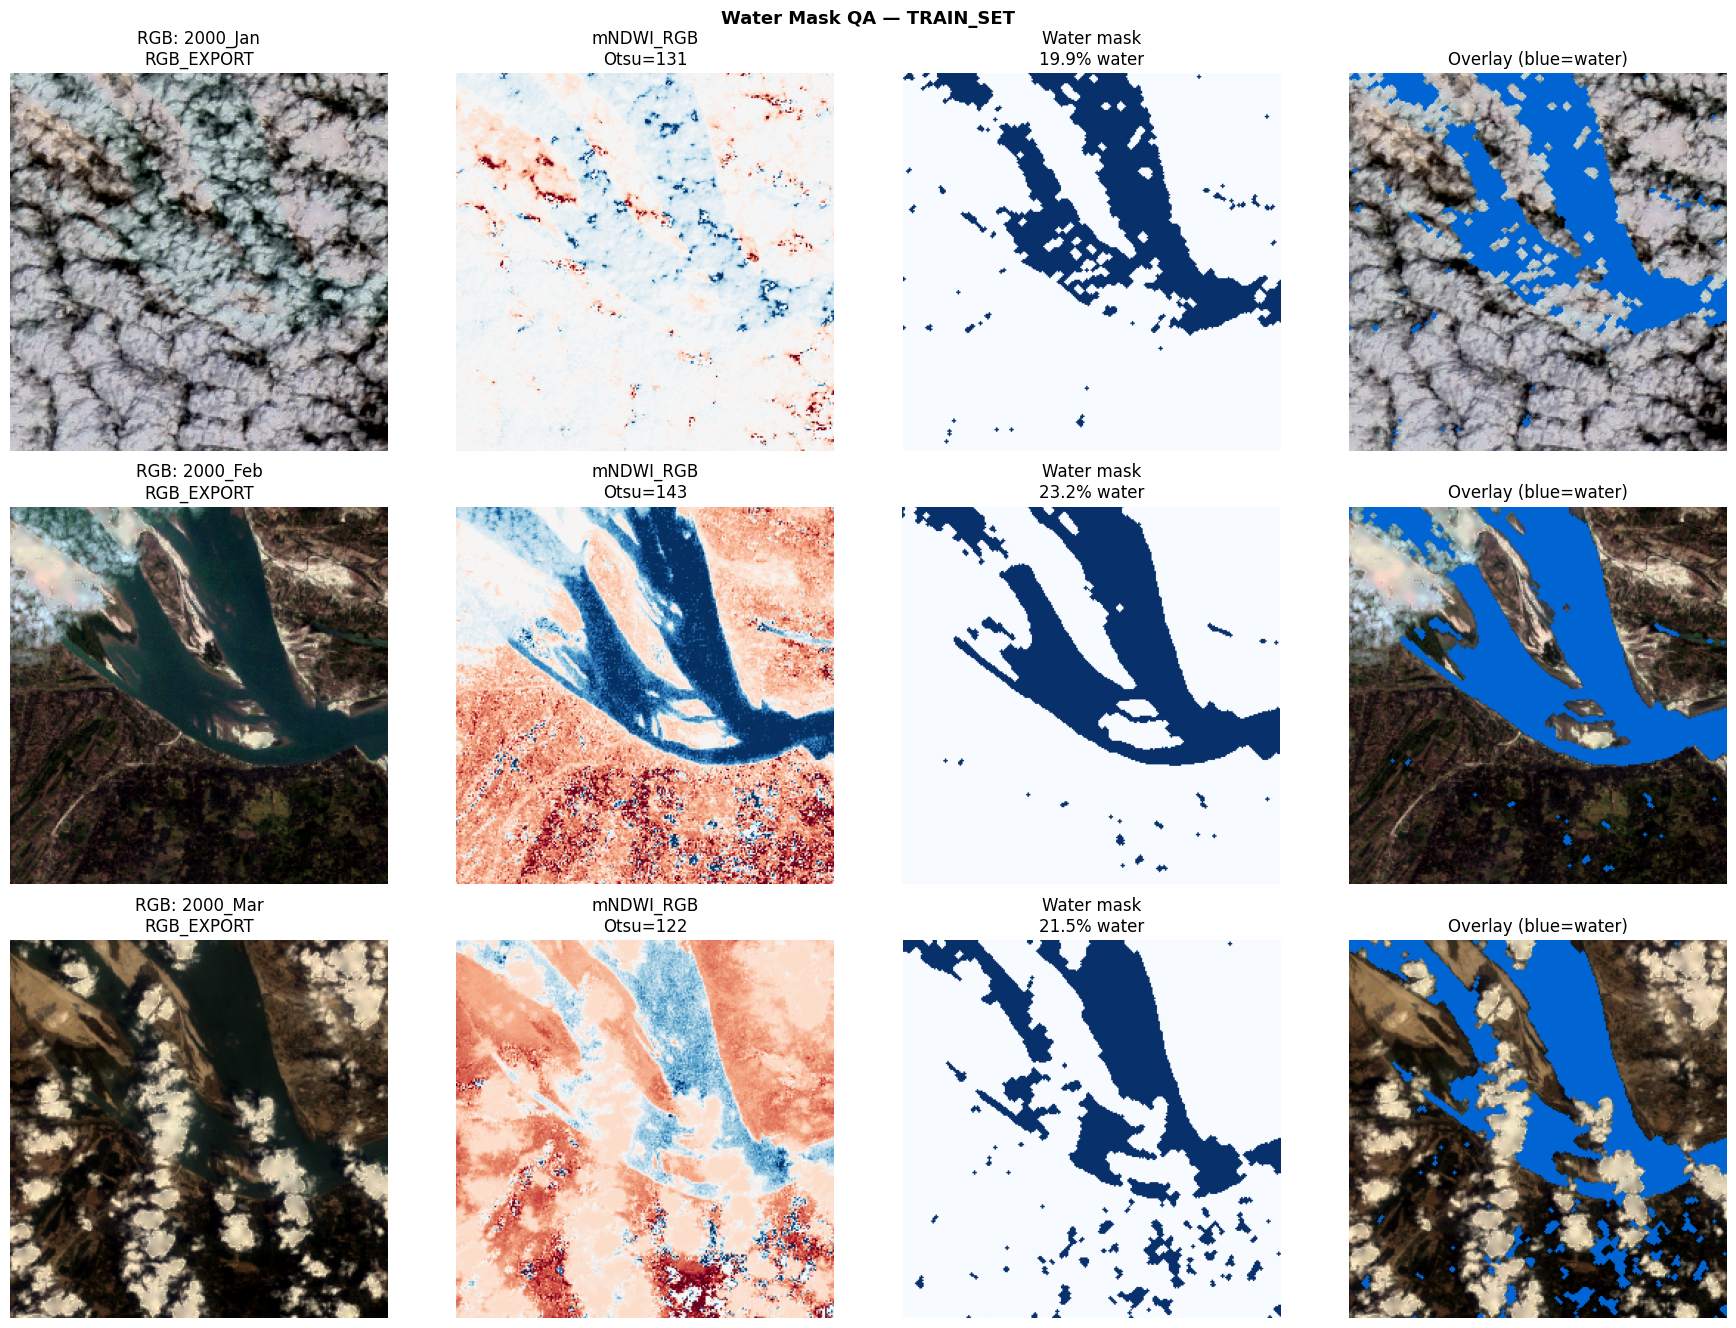

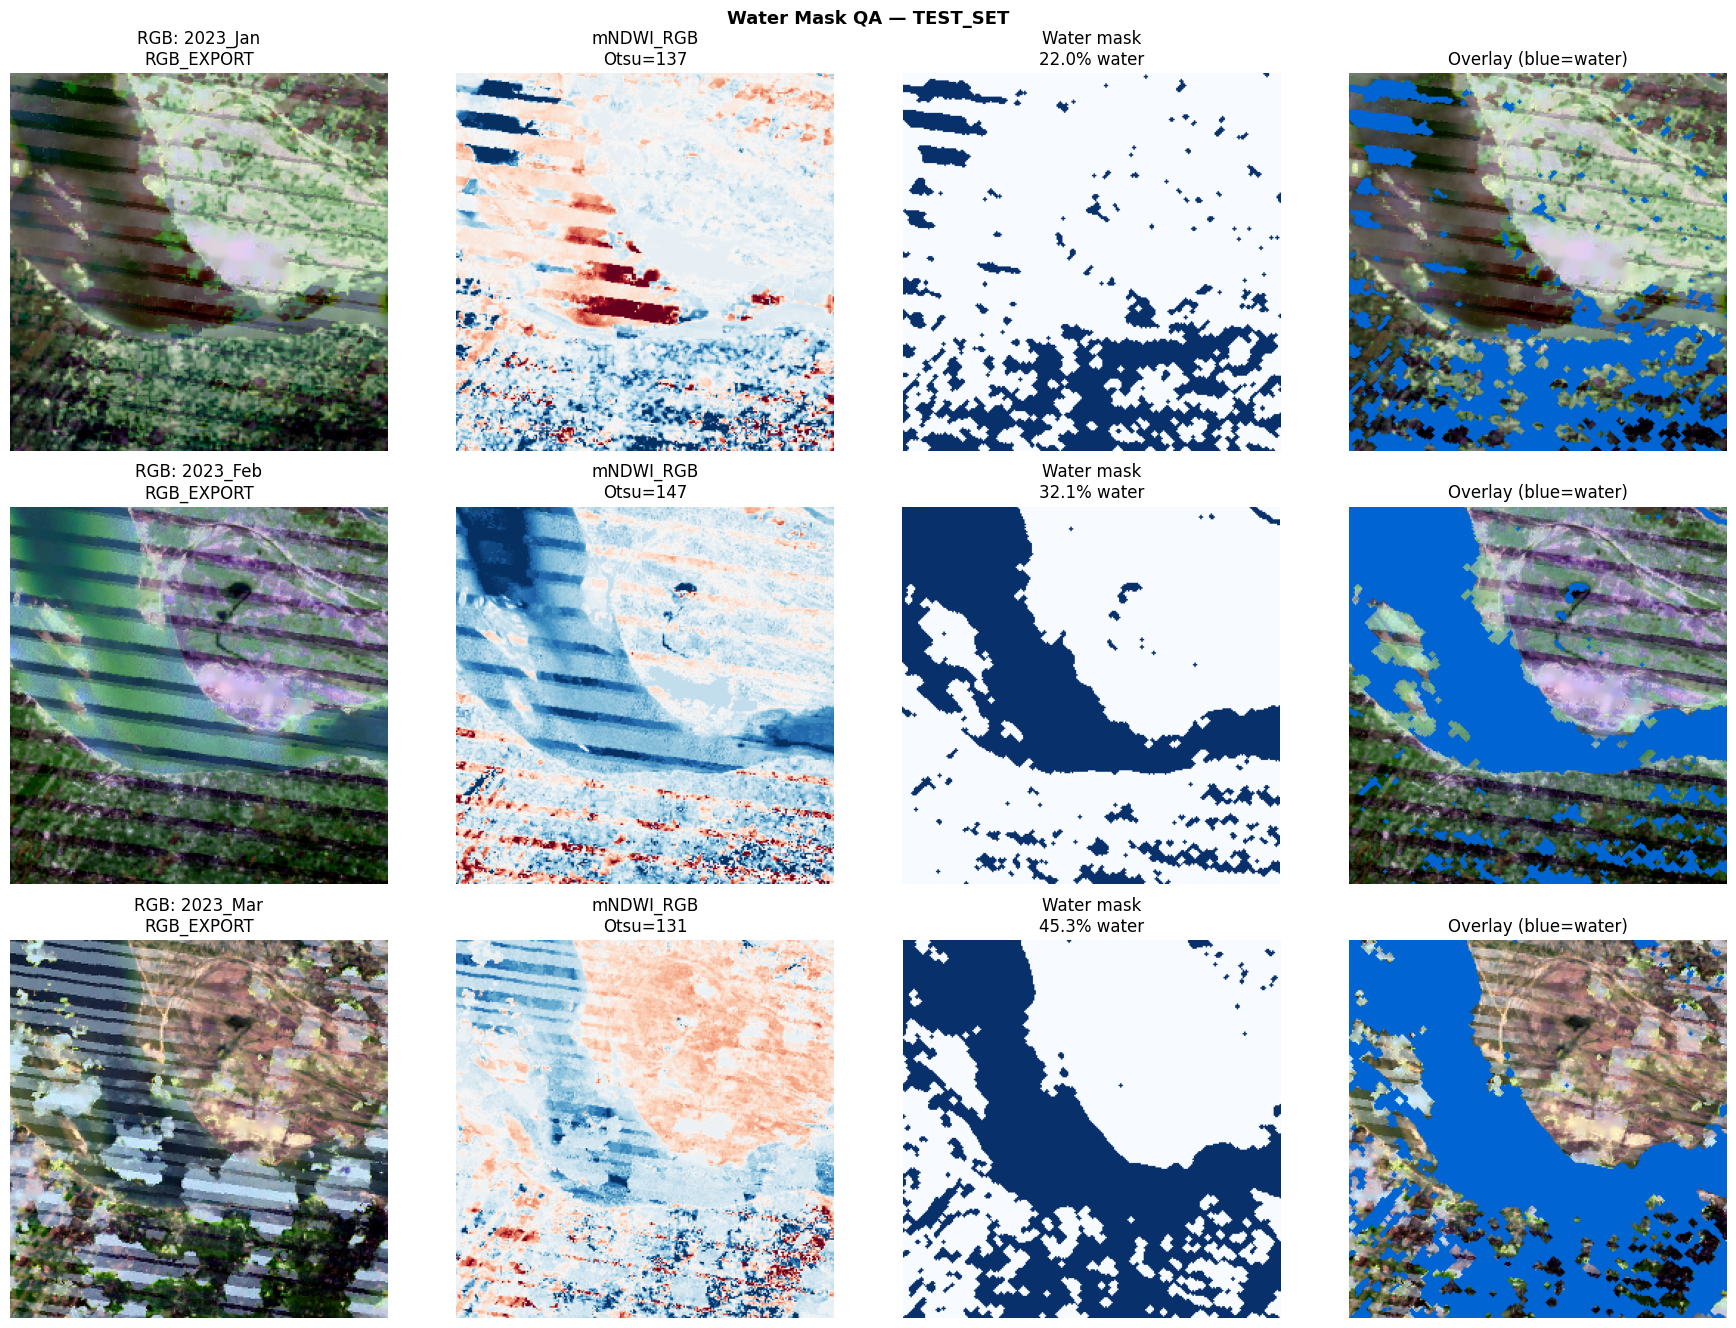

In [ ]:
def sanity_check(cache, split_name, n=3):
    labels=list(cache.keys())[:n]
    if not labels: print(f'No valid images for {split_name}'); return
    fig,axes=plt.subplots(len(labels),4,figsize=(18,4.5*len(labels)))
    if len(labels)==1: axes=[axes]
    for row,lbl in enumerate(labels):
        p=cache[lbl]
        axes[row][0].imshow(p['rgb'])
        axes[row][0].set_title(f'RGB: {lbl}\n{p["itype"]}')
        axes[row][1].imshow(p['water_index'],cmap='RdBu',vmin=-0.5,vmax=0.5)
        axes[row][1].set_title(f'{p["ilabel"]}\nOtsu={p["threshold"]:.0f}')
        axes[row][2].imshow(p['water_mask'],cmap='Blues')
        axes[row][2].set_title(f'Water mask\n{p["water_pct"]:.1%} water')
        ov=p['rgb'].copy(); ov[p['water_mask']]=[0,100,210]
        axes[row][3].imshow(ov)
        axes[row][3].set_title('Overlay (blue=water)')
        for ax in axes[row]: ax.axis('off')
    plt.suptitle(f'Water Mask QA — {split_name}',fontsize=13,fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PATH,f'sanity_{split_name}.png'),
                dpi=120,bbox_inches='tight')
    plt.show()

sanity_check(cache_train,'TRAIN_SET')
sanity_check(cache_test, 'TEST_SET')

---
## PART 10 — Main Analysis Loop (A→O Pipeline)

In [ ]:
def run_pipeline(pairs, cache, split_name):
    """
    Full A→O pipeline for one split.
    Returns DataFrame with geomorphic metrics + climate + VLM + rule labels.
    """
    if not pairs:
        print(f'⚠️  No pairs for {split_name}'); return pd.DataFrame()

    results=[]
    ts=datetime.datetime.now().strftime('%Y%m%d_%H%M')
    print(f'\n🚀 Running {split_name} — {len(pairs)} pairs')

    for idx,(t0,t1) in enumerate(tqdm(pairs)):
        try:
            p0,p1=cache[t0['label']],cache[t1['label']]

            # C–D: Change detection + geomorphic features
            er,dep,m0,m1,valid=change_detect(p0,p1)
            pxkm2=(p0['px_km2']+p1['px_km2'])/2
            gm=geomorphic_metrics(er,dep,m0,m1,valid,pxkm2)

            # E–G: Climate + SPI drought
            s_api=f"{t0['year']}{t0['month']:02d}01"
            e_api=f"{t1['year']}{t1['month']:02d}28"
            env=fetch_climate(LAT,LON,s_api,e_api)
            d_idx,d_lvl,nm=spi(env,t0['month'])

            # H: Rule-based reference label (pseudo-ground truth)
            rl,rc=rule_label(gm)

            # I–J: VLM prompt + inference
            prompt=build_prompt(gm,env,d_idx,d_lvl,nm,t0['label'],t1['label'])
            resp=run_vlm(p0['rgb'],p1['rgb'],prompt)
            vout,pstrat=parse_vlm(resp)

            fallback=False
            if vout is None:
                vout={'risk_level':rl,'confidence':rc,
                      'erosion_evidence':'rule-based fallback',
                      'channel_evidence':'','cause':'','forecast':''}
                pstrat='rule_based_fallback'; fallback=True

            row={
                'split':     split_name,
                'pair':      f"{t0['label']}→{t1['label']}",
                'year_t0':   t0['year'],  'month_t0': t0['month'],
                'year_t1':   t1['year'],  'month_t1': t1['month'],
                'itype':     p0['itype'], 'index':    p0['ilabel'],
                'cloud_t0':  p0['cloud_pct'], 'cloud_t1': p1['cloud_pct'],
                'water_t0':  p0['water_pct'], 'water_t1': p1['water_pct'],
                'px_km2':    round(pxkm2,8),
                **gm,
                'rain_total':  env['rain_total'], 'rain_max':  env['rain_max'],
                'rain_days':   env['rain_days'],  'soil':      env['soil'],
                'temp_c':      env['temp_c'],
                'drought_idx': d_idx, 'drought_lvl': d_lvl,
                'rain_pct_normal': round(env['rain_total']/(nm+1e-9)*100,1),
                # Ground truth proxy
                'rule_risk':   rl,  'rule_conf': rc,
                # VLM output
                'vlm_risk':    vout.get('risk_level','?'),
                'vlm_conf':    float(vout.get('confidence',0)),
                'vlm_cause':   vout.get('cause',''),
                'vlm_erosion': vout.get('erosion_evidence',''),
                'vlm_channel': vout.get('channel_evidence',''),
                'vlm_forecast':vout.get('forecast',''),
                'parse_strat': pstrat, 'fallback': fallback,
                'vlm_raw':     resp[:400],
            }
            results.append(row)

            tqdm.write(
                f"  {t0['label']}→{t1['label']} | "
                f"er={gm['erosion_km2']:.3f}km² sh={gm['shift_m']:.0f}m | "
                f"rule={rl} vlm={vout.get('risk_level','?')} [{pstrat}]")

            # checkpoint every 10 pairs
            if (idx+1)%10==0:
                pd.DataFrame(results).to_csv(
                    os.path.join(OUT_PATH,f'ckpt_{split_name}_{ts}.csv'),index=False)

        except Exception as ex:
            tqdm.write(f'  ❌ {t0["label"]}→{t1["label"]}: {ex}')

    df=pd.DataFrame(results)
    if len(df)>0:
        ok=(df['parse_strat']!='rule_based_fallback').sum()
        print(f'\n✅ {split_name}: {len(df)} pairs | '
              f'VLM parse {ok}/{len(df)} ({ok/len(df)*100:.1f}%)')
        df.to_csv( os.path.join(OUT_PATH,f'results_{split_name}_{ts}.csv'), index=False)
        df.to_excel(os.path.join(OUT_PATH,f'results_{split_name}_{ts}.xlsx'),index=False)
    return df

df_train = run_pipeline(pairs_train, cache_train, 'TRAIN_2000_2022')
df_test  = run_pipeline(pairs_test,  cache_test,  'TEST_2023_2025')


🚀 Running TRAIN_2000_2022 — 127 pairs


  1%|          | 1/127 [00:11<24:57, 11.89s/it]

  2000_Jan→2000_Feb | er=1.835km² sh=76m | rule=MEDIUM vlm=LOW [vlm_parsed]


  2%|▏         | 2/127 [00:25<26:30, 12.72s/it]

  2000_Feb→2000_Mar | er=2.564km² sh=263m | rule=HIGH vlm=LOW [vlm_parsed]


  2%|▏         | 3/127 [00:35<23:50, 11.54s/it]

... (283 outputs left out)

 95%|█████████▍| 18/19 [03:44<00:13, 13.18s/it]

  2025_Jun→2025_Jul | er=10.833km² sh=436m | rule=HIGH vlm=LOW [vlm_parsed]


100%|██████████| 19/19 [03:57<00:00, 12.51s/it]

  2025_Jul→2025_Aug | er=3.723km² sh=816m | rule=HIGH vlm=LOW [vlm_parsed]

✅ TEST_2023_2025: 19 pairs | VLM parse 19/19 (100.0%)


---
## PART 11 — Research-Grade Evaluation
### 11a. Per-Split Metrics (Precision · Recall · F1 · Kappa)


  EVALUATION — TRAIN_2000_2022
  Pairs evaluated : 127 / 127
  VLM parse rate  : 100.0%  (127/127)
  Accuracy        : 0.063
  Cohen's Kappa   : 0.000  (Slight)
              precision    recall  f1-score   support

         LOW       0.06      1.00      0.12         8
      MEDIUM       0.00      0.00      0.00        16
        HIGH       0.00      0.00      0.00       103

    accuracy                           0.06       127
   macro avg       0.02      0.33      0.04       127
weighted avg       0.00      0.06      0.01       127



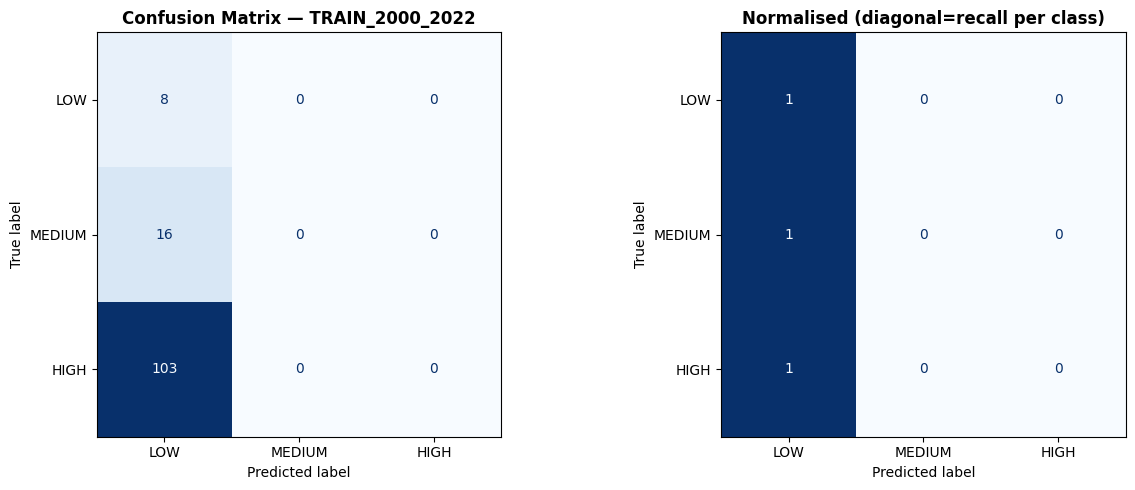

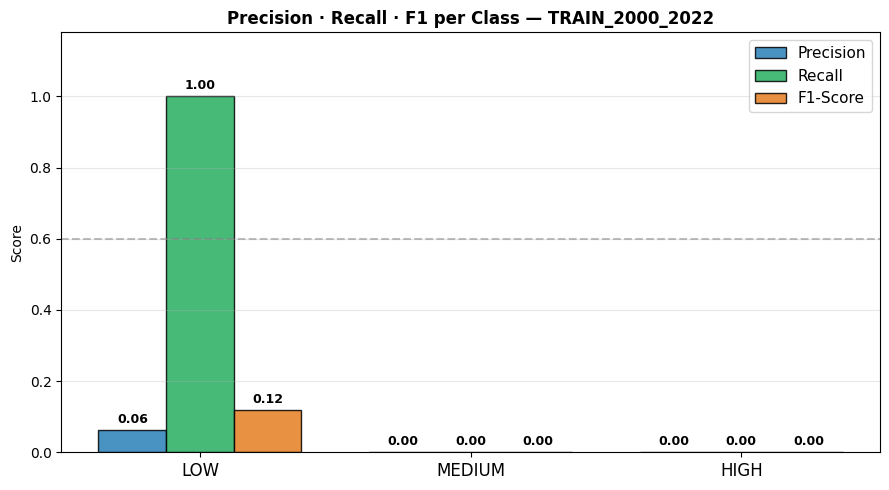

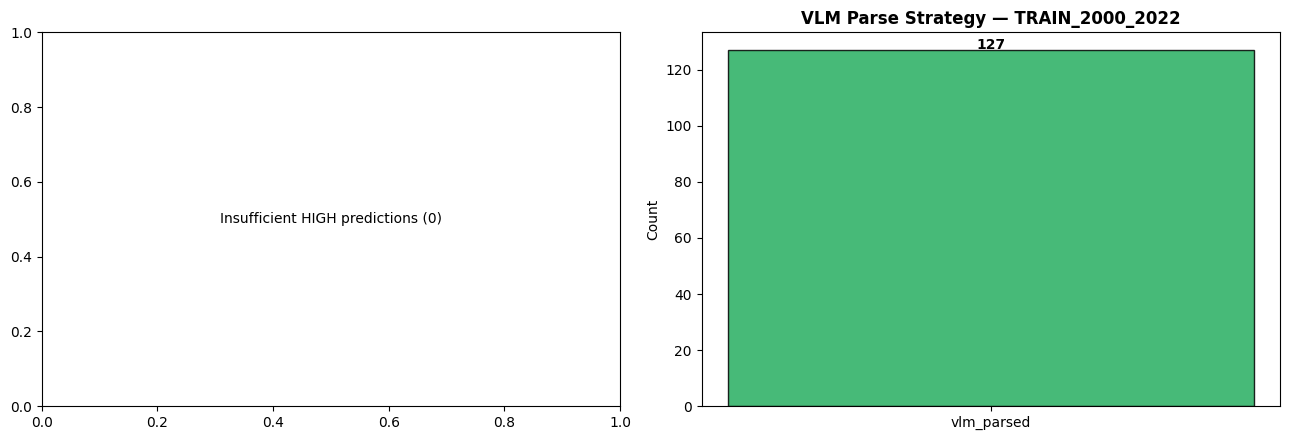

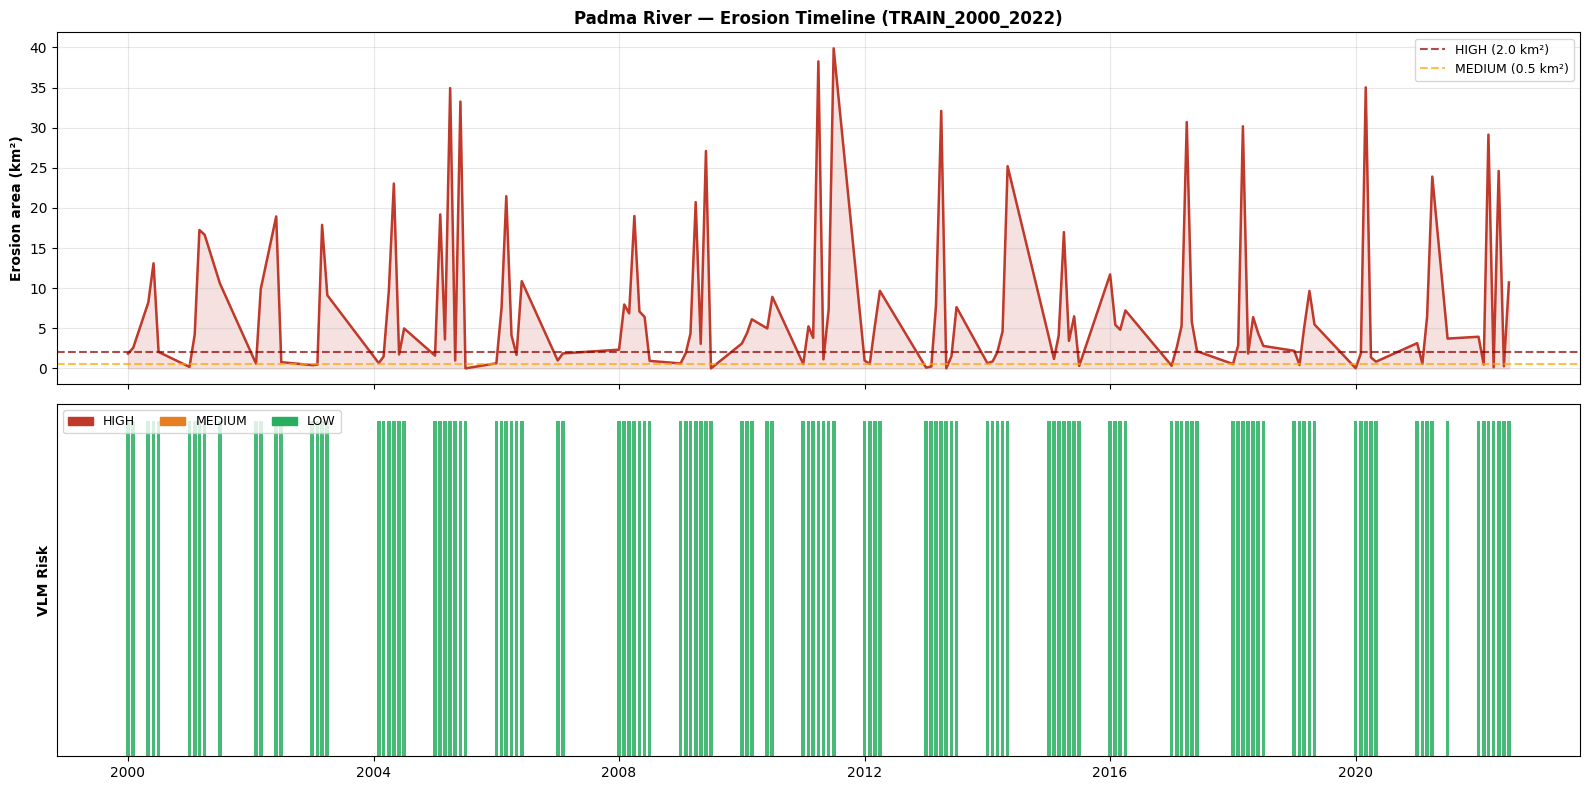


  EVALUATION — TEST_2023_2025
  Pairs evaluated : 19 / 19
  VLM parse rate  : 100.0%  (19/19)
  Accuracy        : 0.053
  Cohen's Kappa   : 0.000  (Slight)
              precision    recall  f1-score   support

         LOW       0.05      1.00      0.10         1
      MEDIUM       0.00      0.00      0.00         1
        HIGH       0.00      0.00      0.00        17

    accuracy                           0.05        19
   macro avg       0.02      0.33      0.03        19
weighted avg       0.00      0.05      0.01        19



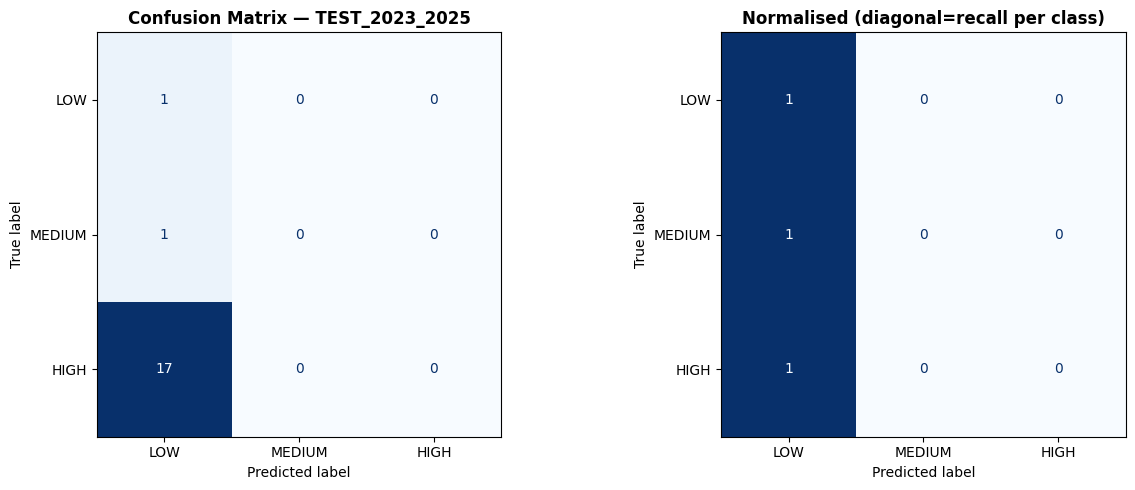

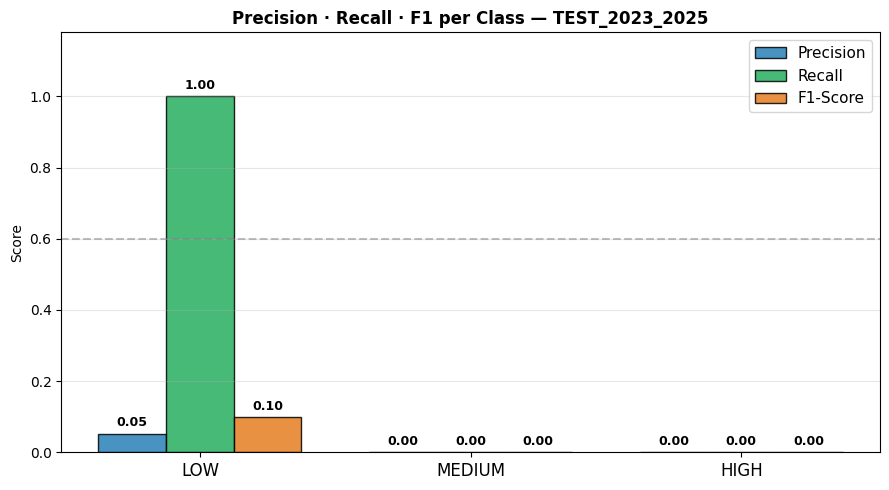

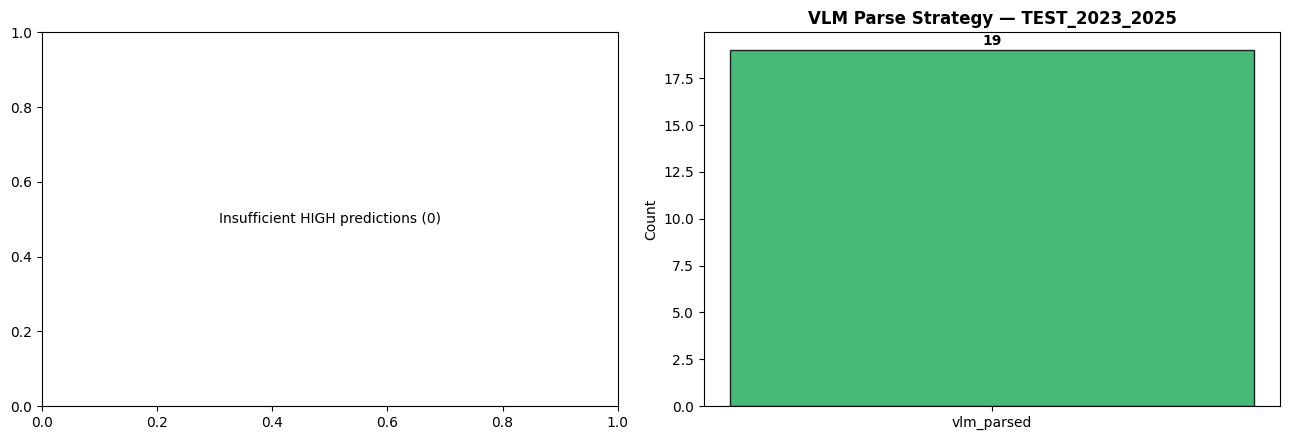

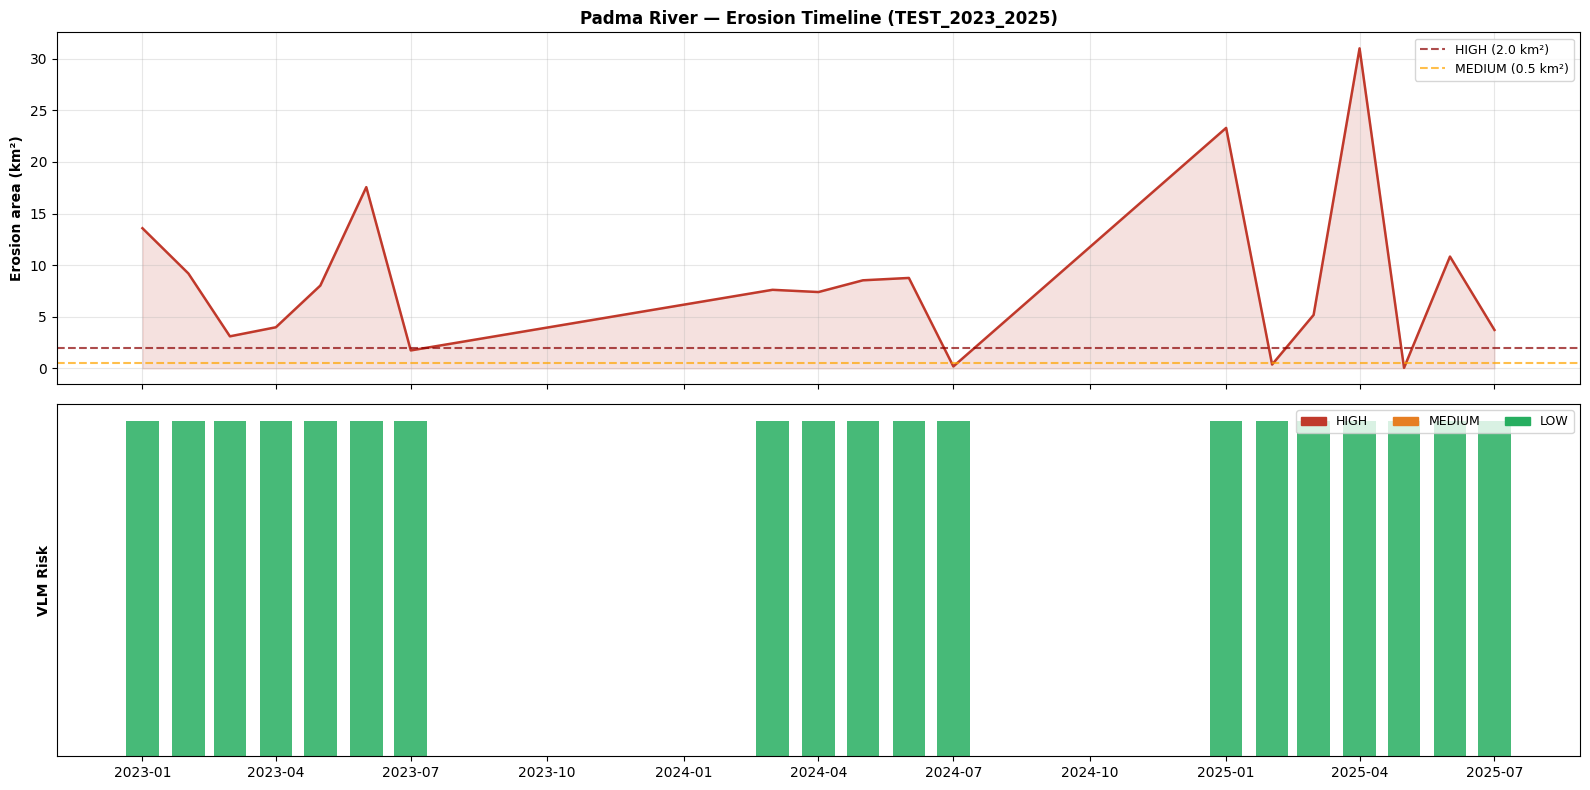

In [ ]:
def evaluate(df, split_name):
    """
    Full evaluation suite for one split.
    Saves all figures. Returns metrics dict for summary table.
    """
    if df is None or len(df)==0:
        print(f'⚠️  {split_name}: empty'); return {}

    ev=df[df['vlm_risk'].isin(RISK_ORDER)&df['rule_risk'].isin(RISK_ORDER)].copy()
    if len(ev)==0:
        print(f'⚠️  {split_name}: no evaluable rows'); return {}

    yt,yp = ev['rule_risk'].values, ev['vlm_risk'].values
    parse_ok   = (ev['parse_strat']!='rule_based_fallback').sum()
    parse_rate = parse_ok/len(df)

    kappa = cohen_kappa_score(yt,yp,labels=RISK_ORDER)
    rd    = classification_report(yt,yp,labels=RISK_ORDER,zero_division=0,output_dict=True)
    acc   = rd['accuracy']

    sep='='*60
    print(f'\n{sep}')
    print(f'  EVALUATION — {split_name}')
    print(f'  Pairs evaluated : {len(ev)} / {len(df)}')
    print(f'  VLM parse rate  : {parse_rate:.1%}  ({parse_ok}/{len(df)})')
    print(f'  Accuracy        : {acc:.3f}')
    kap_txt=('Slight' if kappa<0.2 else 'Fair' if kappa<0.4 else
             'Moderate' if kappa<0.6 else 'Substantial' if kappa<0.8 else 'Almost Perfect')
    print(f"  Cohen's Kappa   : {kappa:.3f}  ({kap_txt})")
    print(sep)
    print(classification_report(yt,yp,labels=RISK_ORDER,zero_division=0))

    # ── Figure 1: Confusion matrices ─────────────────────────────────────────
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    cm=confusion_matrix(yt,yp,labels=RISK_ORDER)
    ConfusionMatrixDisplay(cm,display_labels=RISK_ORDER).plot(
        ax=axes[0],colorbar=False,cmap='Blues')
    axes[0].set_title(f'Confusion Matrix — {split_name}',fontweight='bold')
    cmn=cm/(cm.sum(axis=1,keepdims=True)+1e-9)
    ConfusionMatrixDisplay(np.round(cmn,2),display_labels=RISK_ORDER).plot(
        ax=axes[1],colorbar=False,cmap='Blues')
    axes[1].set_title('Normalised (diagonal=recall per class)',fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PATH,f'fig_cm_{split_name}.png'),dpi=150,bbox_inches='tight')
    plt.show()

    # ── Figure 2: Per-class Precision · Recall · F1 ──────────────────────────
    classes=[c for c in RISK_ORDER if c in rd]
    prec=[rd[c]['precision'] for c in classes]
    rec =[rd[c]['recall']    for c in classes]
    f1s =[rd[c]['f1-score']  for c in classes]
    x=np.arange(len(classes)); w=0.25
    fig,ax=plt.subplots(figsize=(9,5))
    b1=ax.bar(x-w,prec,w,label='Precision',color='#2980b9',alpha=0.85,edgecolor='k')
    b2=ax.bar(x,  rec, w,label='Recall',   color='#27ae60',alpha=0.85,edgecolor='k')
    b3=ax.bar(x+w,f1s, w,label='F1-Score', color='#e67e22',alpha=0.85,edgecolor='k')
    ax.set_xticks(x); ax.set_xticklabels(classes,fontsize=12)
    ax.set_ylim(0,1.18); ax.legend(fontsize=11)
    ax.set_title(f'Precision · Recall · F1 per Class — {split_name}',fontweight='bold')
    ax.axhline(0.6,linestyle='--',color='gray',alpha=0.5,label='0.6 reference')
    ax.set_ylabel('Score'); ax.grid(axis='y',alpha=0.3)
    for i,(p,r,f) in enumerate(zip(prec,rec,f1s)):
        ax.text(i-w,p+0.02,f'{p:.2f}',ha='center',fontsize=9,fontweight='bold')
        ax.text(i,  r+0.02,f'{r:.2f}',ha='center',fontsize=9,fontweight='bold')
        ax.text(i+w,f+0.02,f'{f:.2f}',ha='center',fontsize=9,fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PATH,f'fig_prf1_{split_name}.png'),dpi=150,bbox_inches='tight')
    plt.show()

    # ── Figure 3: Confidence calibration + parse breakdown ───────────────────
    ev2=ev.copy()
    ev2['conf']=pd.to_numeric(ev2['vlm_conf'],errors='coerce').fillna(0.5)
    ev2['high_true']=(ev2['rule_risk']=='HIGH').astype(int)
    hi=ev2[ev2['vlm_risk']=='HIGH']

    fig,axes=plt.subplots(1,2,figsize=(13,4.5))
    if len(hi)>=10:
        try:
            pt,pp=calibration_curve(hi['high_true'],hi['conf'],n_bins=5,strategy='uniform')
            axes[0].plot(pp,pt,'s-',lw=2,color='#2980b9',label='VLM')
            axes[0].plot([0,1],[0,1],'k--',label='Perfect calibration')
            bs=brier_score_loss(hi['high_true'],hi['conf'])
            axes[0].set_xlabel(f'Mean predicted confidence  [Brier score={bs:.3f}]')
            axes[0].set_title(f'Confidence Calibration (HIGH class)\n{split_name}',fontweight='bold')
            axes[0].legend(); axes[0].set_ylabel('Fraction correct')
            axes[0].grid(alpha=0.3)
        except Exception as ce:
            axes[0].text(0.5,0.5,str(ce),ha='center',va='center',transform=axes[0].transAxes)
    else:
        axes[0].text(0.5,0.5,f'Insufficient HIGH predictions ({len(hi)})',
                     ha='center',va='center',transform=axes[0].transAxes)
    pc=df['parse_strat'].value_counts()
    cols_bar=['#27ae60','#3498db','#e67e22','#e74c3c','#95a5a6']
    axes[1].bar(pc.index,pc.values,color=cols_bar[:len(pc)],edgecolor='k',alpha=0.85)
    axes[1].set_title(f'VLM Parse Strategy — {split_name}',fontweight='bold')
    axes[1].set_ylabel('Count')
    for i,v in enumerate(pc.values):
        axes[1].text(i,v+0.3,str(v),ha='center',fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PATH,f'fig_calib_{split_name}.png'),dpi=150,bbox_inches='tight')
    plt.show()

    # ── Figure 4: Temporal erosion timeline ──────────────────────────────────
    df2=df.copy()
    df2['date']=pd.to_datetime(
        df2[['year_t0','month_t0']].rename(columns={'year_t0':'year','month_t0':'month'})
        .assign(day=1))
    fig,axes=plt.subplots(2,1,figsize=(16,8),sharex=True)
    axes[0].fill_between(df2['date'],df2['erosion_km2'],alpha=0.15,color='#c0392b')
    axes[0].plot(df2['date'],df2['erosion_km2'],color='#c0392b',lw=1.8)
    axes[0].axhline(RISK_HIGH_KM2,  ls='--',color='darkred',alpha=0.7,
                    label=f'HIGH ({RISK_HIGH_KM2} km²)')
    axes[0].axhline(RISK_MEDIUM_KM2,ls='--',color='orange', alpha=0.7,
                    label=f'MEDIUM ({RISK_MEDIUM_KM2} km²)')
    axes[0].set_ylabel('Erosion area (km²)',fontweight='bold')
    axes[0].set_title(f'Padma River — Erosion Timeline ({split_name})',fontweight='bold')
    axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)
    for _,rw in df2.iterrows():
        axes[1].bar(rw['date'],1,width=22,
                    color=RISK_COLOR.get(rw['vlm_risk'],'gray'),alpha=0.85)
    axes[1].set_yticks([]); axes[1].set_ylabel('VLM Risk',fontweight='bold')
    patches=[mpatches.Patch(color=v,label=k) for k,v in RISK_COLOR.items() if k!='?']
    axes[1].legend(handles=patches,ncol=3,fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PATH,f'fig_timeline_{split_name}.png'),dpi=150,bbox_inches='tight')
    plt.show()

    return {
        'split':      split_name,
        'n_pairs':    len(ev),
        'parse_rate': round(parse_rate,4),
        'accuracy':   round(acc,4),
        'kappa':      round(kappa,4),
        'macro_f1':   round(rd['macro avg']['f1-score'],4),
        'high_prec':  round(rd.get('HIGH',{}).get('precision',0),4),
        'high_rec':   round(rd.get('HIGH',{}).get('recall',0),4),
        'high_f1':    round(rd.get('HIGH',{}).get('f1-score',0),4),
        'med_prec':   round(rd.get('MEDIUM',{}).get('precision',0),4),
        'med_rec':    round(rd.get('MEDIUM',{}).get('recall',0),4),
        'med_f1':     round(rd.get('MEDIUM',{}).get('f1-score',0),4),
        'low_prec':   round(rd.get('LOW',{}).get('precision',0),4),
        'low_rec':    round(rd.get('LOW',{}).get('recall',0),4),
        'low_f1':     round(rd.get('LOW',{}).get('f1-score',0),4),
    }

m_train = evaluate(df_train,'TRAIN_2000_2022')
m_test  = evaluate(df_test, 'TEST_2023_2025')

### 11b. Leave-One-Year-Out Cross-Validation (Training Set)


LOYO-CV Results:
 year  n  vlm_acc  baseline  kappa  high_f1  macro_f1
 2000  5    0.000     0.800    0.0      0.0     0.000
 2001  5    0.200     0.800    0.0      0.0     0.111
 2002  4    0.000     0.750    0.0      0.0     0.000
 2003  4    0.500     0.500    0.0      0.0     0.222
 2004  6    0.000     0.833    0.0      0.0     0.000
 2005  7    0.000     1.000    0.0      0.0     0.000
 2006  6    0.000     0.833    0.0      0.0     0.000
 2007  2    0.000     0.500    0.0      0.0     0.000
 2008  7    0.000     1.000    0.0      0.0     0.000
 2009  7    0.000     0.714    0.0      0.0     0.000
 2010  5    0.000     1.000    0.0      0.0     0.000
 2011  7    0.000     0.857    0.0      0.0     0.000
 2012  4    0.000     0.500    0.0      0.0     0.000
 2013  7    0.286     0.714    0.0      0.0     0.148
 2014  5    0.000     0.800    0.0      0.0     0.000
 2015  7    0.000     0.857    0.0      0.0     0.000
 2016  4    0.000     1.000    0.0      0.0     0.000
 2017  6  

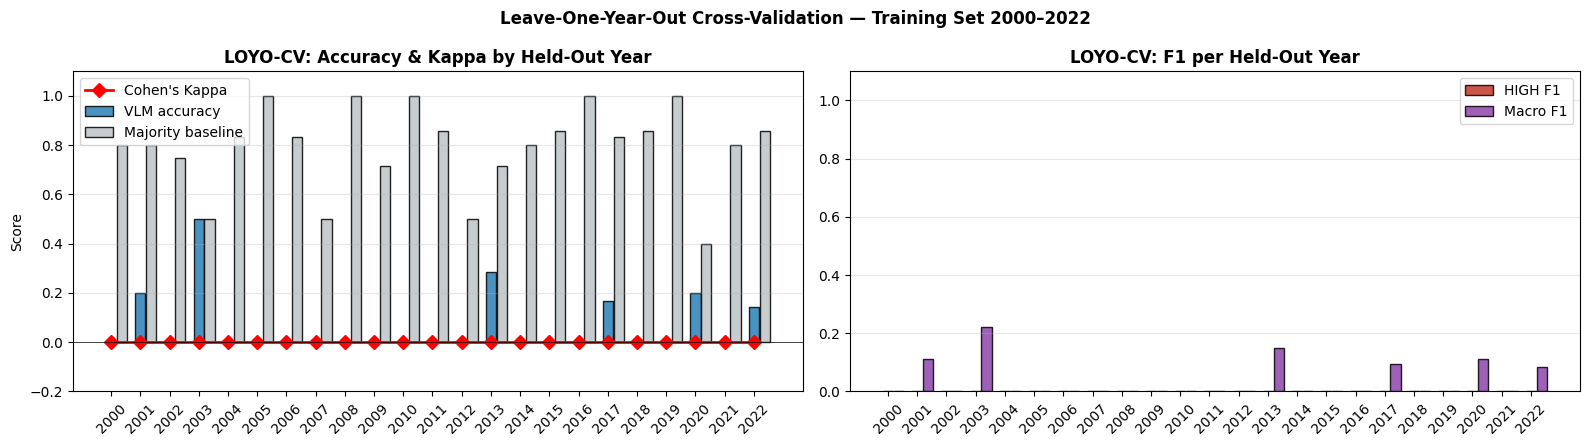

In [ ]:
def loyo_cv(df):
    """
    Leave-One-Year-Out CV on the training set.
    For each year Y: train = all other years, test = year Y.
    Quantifies temporal generalisation within the training period.
    """
    ev=df[df['vlm_risk'].isin(RISK_ORDER)&df['rule_risk'].isin(RISK_ORDER)].copy()
    if len(ev)<10: print('Insufficient data for LOYO-CV (need ≥10 pairs)'); return pd.DataFrame()

    years=sorted(ev['year_t0'].unique())
    rows=[]
    for yr in years:
        te=ev[ev['year_t0']==yr]; tr=ev[ev['year_t0']!=yr]
        if len(te)==0: continue
        maj=tr['rule_risk'].mode()[0] if len(tr)>0 else 'HIGH'
        base=accuracy_score(te['rule_risk'],[maj]*len(te))
        vacc=accuracy_score(te['rule_risk'],te['vlm_risk'])
        kap =cohen_kappa_score(te['rule_risk'],te['vlm_risk'],
                               labels=RISK_ORDER) if len(te)>1 else 0.0
        rd  =classification_report(te['rule_risk'],te['vlm_risk'],
                                   labels=RISK_ORDER,zero_division=0,output_dict=True)
        rows.append({'year':int(yr),'n':len(te),
                     'vlm_acc':round(vacc,3),'baseline':round(base,3),
                     'kappa':round(kap,3),
                     'high_f1':round(rd.get('HIGH',{}).get('f1-score',0),3),
                     'macro_f1':round(rd['macro avg']['f1-score'],3)})

    loyo=pd.DataFrame(rows)
    print('\nLOYO-CV Results:')
    print(loyo.to_string(index=False))
    print(f'\nMean VLM accuracy : {loyo["vlm_acc"].mean():.3f} ± {loyo["vlm_acc"].std():.3f}')
    print(f'Mean baseline     : {loyo["baseline"].mean():.3f}')
    print(f'Mean Kappa        : {loyo["kappa"].mean():.3f} ± {loyo["kappa"].std():.3f}')
    print(f'Mean HIGH F1      : {loyo["high_f1"].mean():.3f}')

    # ── LOYO plot ────────────────────────────────────────────────────────────
    fig,axes=plt.subplots(1,2,figsize=(16,4.5))
    x=range(len(loyo))
    axes[0].bar(x,loyo['vlm_acc'],width=0.35,
                label='VLM accuracy',color='#2980b9',alpha=0.85,edgecolor='k')
    axes[0].bar([i+0.37 for i in x],loyo['baseline'],width=0.35,
                label='Majority baseline',color='#bdc3c7',alpha=0.85,edgecolor='k')
    axes[0].plot(x,loyo['kappa'],'rD-',lw=2,ms=7,label="Cohen's Kappa")
    axes[0].axhline(0,color='k',lw=0.5)
    axes[0].set_xticks(x); axes[0].set_xticklabels(loyo['year'],rotation=45)
    axes[0].set_title('LOYO-CV: Accuracy & Kappa by Held-Out Year',fontweight='bold')
    axes[0].set_ylabel('Score'); axes[0].legend(); axes[0].set_ylim(-0.2,1.1)
    axes[0].grid(axis='y',alpha=0.3)

    axes[1].bar(x,loyo['high_f1'],width=0.35,
                label='HIGH F1',color='#c0392b',alpha=0.85,edgecolor='k')
    axes[1].bar([i+0.37 for i in x],loyo['macro_f1'],width=0.35,
                label='Macro F1',color='#8e44ad',alpha=0.85,edgecolor='k')
    axes[1].set_xticks(x); axes[1].set_xticklabels(loyo['year'],rotation=45)
    axes[1].set_title('LOYO-CV: F1 per Held-Out Year',fontweight='bold')
    axes[1].legend(); axes[1].set_ylim(0,1.1)
    axes[1].grid(axis='y',alpha=0.3)

    plt.suptitle('Leave-One-Year-Out Cross-Validation — Training Set 2000–2022',
                 fontsize=12,fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PATH,'fig_loyo_cv.png'),dpi=150,bbox_inches='tight')
    plt.show()
    return loyo

loyo_df = loyo_cv(df_train) if len(df_train)>0 else pd.DataFrame()

### 11c. Train vs Test Comparison — The Key Paper Figure


  TRAIN vs TEST VALIDATION SUMMARY
          split  n_pairs  parse_rate  accuracy  kappa  macro_f1  high_prec  high_rec  high_f1  med_f1  low_f1
TRAIN_2000_2022      127         1.0    0.0630    0.0    0.0395        0.0       0.0      0.0     0.0  0.1185
 TEST_2023_2025       19         1.0    0.0526    0.0    0.0333        0.0       0.0      0.0     0.0  0.1000


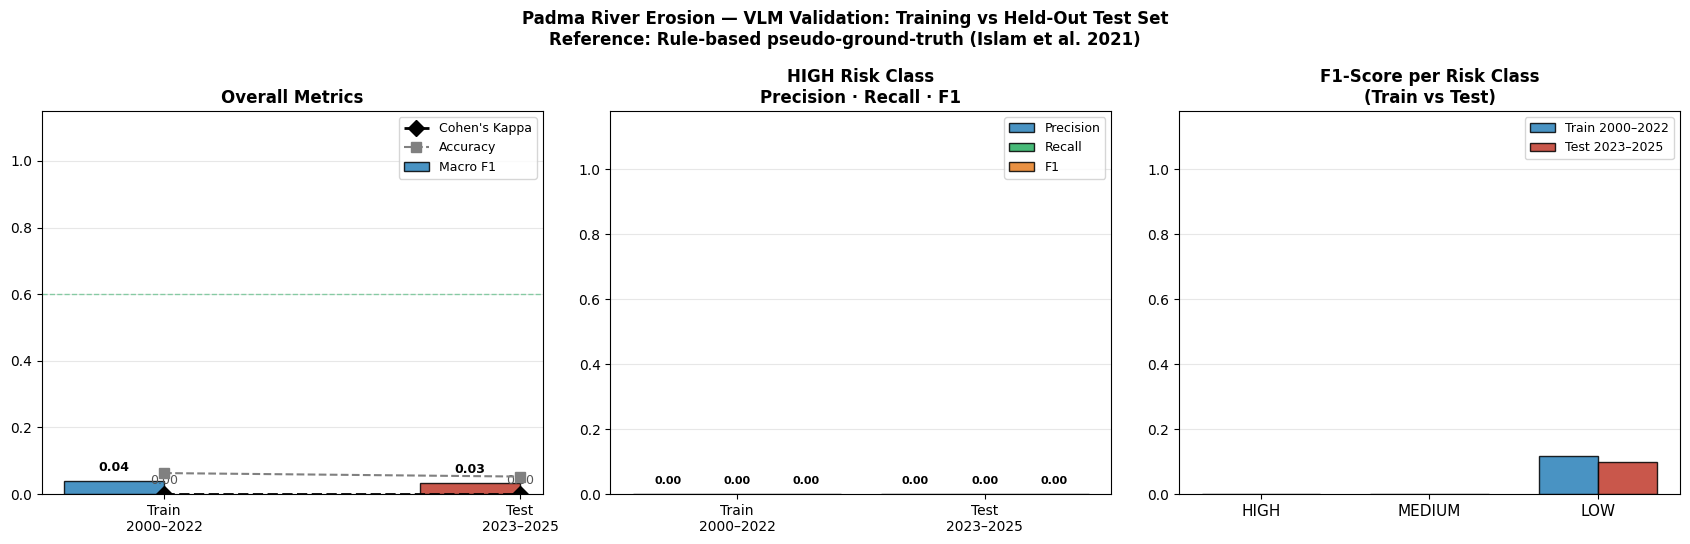

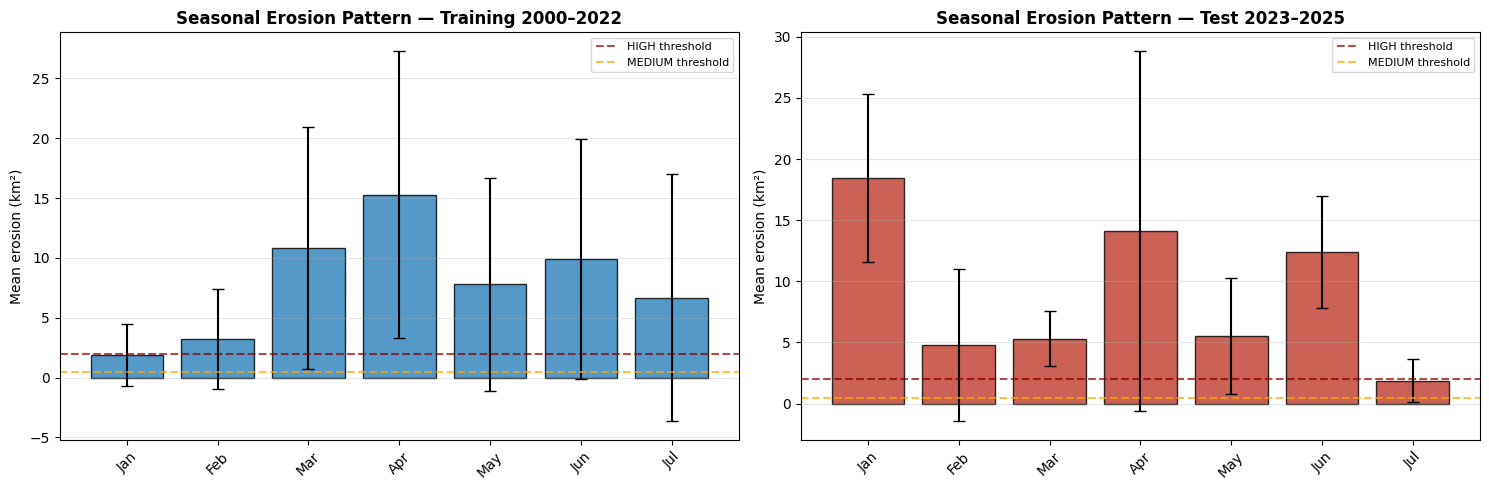

In [ ]:
all_m=[m for m in [m_train,m_test] if m]

if all_m:
    summary=pd.DataFrame(all_m)

    print('\n'+'='*72)
    print('  TRAIN vs TEST VALIDATION SUMMARY')
    print('='*72)
    cols=['split','n_pairs','parse_rate','accuracy','kappa','macro_f1',
          'high_prec','high_rec','high_f1','med_f1','low_f1']
    print(summary[cols].to_string(index=False))
    print('='*72)

    # ── Main comparison figure ────────────────────────────────────────────────
    splits=['Train\n2000–2022','Test\n2023–2025']
    colors_s=['#2980b9','#c0392b']
    x=np.arange(2); w=0.28

    fig,axes=plt.subplots(1,3,figsize=(17,5.5))
    fig.suptitle('Padma River Erosion — VLM Validation: Training vs Held-Out Test Set\n'
                 'Reference: Rule-based pseudo-ground-truth (Islam et al. 2021)',
                 fontsize=12,fontweight='bold')

    # Plot 1: Overall metrics
    axes[0].bar(x-w/2,summary['macro_f1'],w,label='Macro F1',
                color=colors_s,alpha=0.85,edgecolor='k')
    axes[0].plot(x,summary['kappa'],'D--k',lw=2,ms=8,label="Cohen's Kappa",zorder=5)
    axes[0].plot(x,summary['accuracy'],'s--',color='gray',lw=1.5,ms=7,
                 label='Accuracy',zorder=5)
    axes[0].set_xticks(x); axes[0].set_xticklabels(splits,fontsize=10)
    axes[0].set_ylim(0,1.15); axes[0].set_title('Overall Metrics',fontweight='bold')
    axes[0].axhline(0.6,ls='--',color='#27ae60',alpha=0.5,lw=1)
    axes[0].legend(fontsize=9); axes[0].grid(axis='y',alpha=0.3)
    for i,(f,k) in enumerate(zip(summary['macro_f1'],summary['kappa'])):
        axes[0].text(i-w/2,f+0.03,f'{f:.2f}',ha='center',fontsize=9,fontweight='bold')
        axes[0].text(i,    k+0.03,f'{k:.2f}',ha='center',fontsize=9,color='#555')

    # Plot 2: HIGH class P/R/F1
    axes[1].bar(x-w,summary['high_prec'],w,label='Precision',color='#2980b9',alpha=0.85,edgecolor='k')
    axes[1].bar(x,  summary['high_rec'], w,label='Recall',   color='#27ae60',alpha=0.85,edgecolor='k')
    axes[1].bar(x+w,summary['high_f1'],  w,label='F1',       color='#e67e22',alpha=0.85,edgecolor='k')
    axes[1].set_xticks(x); axes[1].set_xticklabels(splits,fontsize=10)
    axes[1].set_ylim(0,1.18); axes[1].set_title('HIGH Risk Class\nPrecision · Recall · F1',fontweight='bold')
    axes[1].legend(fontsize=9); axes[1].grid(axis='y',alpha=0.3)
    for i,(p,r,f) in enumerate(zip(summary['high_prec'],summary['high_rec'],summary['high_f1'])):
        axes[1].text(i-w,p+0.03,f'{p:.2f}',ha='center',fontsize=8,fontweight='bold')
        axes[1].text(i,  r+0.03,f'{r:.2f}',ha='center',fontsize=8,fontweight='bold')
        axes[1].text(i+w,f+0.03,f'{f:.2f}',ha='center',fontsize=8,fontweight='bold')

    # Plot 3: All classes F1 side by side
    classes=['HIGH','MEDIUM','LOW']
    f1_cols=['high_f1','med_f1','low_f1']
    xc=np.arange(len(classes)); wc=0.35
    for si,(sname,sc) in enumerate(zip(splits,colors_s)):
        f1vals=[summary.iloc[si][fc] for fc in f1_cols]
        axes[2].bar(xc+(si-0.5)*wc,f1vals,wc,label=sname.replace('\n',' '),
                    color=sc,alpha=0.85,edgecolor='k')
    axes[2].set_xticks(xc); axes[2].set_xticklabels(classes,fontsize=11)
    axes[2].set_ylim(0,1.18); axes[2].set_title('F1-Score per Risk Class\n(Train vs Test)',fontweight='bold')
    axes[2].legend(fontsize=9); axes[2].grid(axis='y',alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PATH,'fig_train_vs_test_main.png'),dpi=150,bbox_inches='tight')
    plt.show()

    # ── Seasonal analysis ─────────────────────────────────────────────────────
    fig,axes=plt.subplots(1,2,figsize=(15,5))

    for ax,df2,sn,sc in [(axes[0],df_train,'Training 2000–2022','#2980b9'),
                          (axes[1],df_test,'Test 2023–2025','#c0392b')]:
        if df2 is None or len(df2)==0: continue
        monthly=df2.groupby('month_t0')['erosion_km2'].agg(['mean','std','count'])
        mn=[MONTH_ABBR.get(i,str(i)) for i in monthly.index]
        ax.bar(mn,monthly['mean'],color=sc,alpha=0.8,edgecolor='k')
        ax.errorbar(mn,monthly['mean'],yerr=monthly['std'],fmt='none',
                    color='k',capsize=4,lw=1.5)
        ax.axhline(RISK_HIGH_KM2,  ls='--',color='darkred',alpha=0.7,label='HIGH threshold')
        ax.axhline(RISK_MEDIUM_KM2,ls='--',color='orange', alpha=0.7,label='MEDIUM threshold')
        ax.set_title(f'Seasonal Erosion Pattern — {sn}',fontweight='bold')
        ax.set_ylabel('Mean erosion (km²)'); ax.legend(fontsize=8)
        ax.grid(axis='y',alpha=0.3)
        ax.tick_params(axis='x',rotation=45)

    plt.tight_layout()
    plt.savefig(os.path.join(OUT_PATH,'fig_seasonal.png'),dpi=150,bbox_inches='tight')
    plt.show()

### 11d. Drought Index vs Erosion Analysis

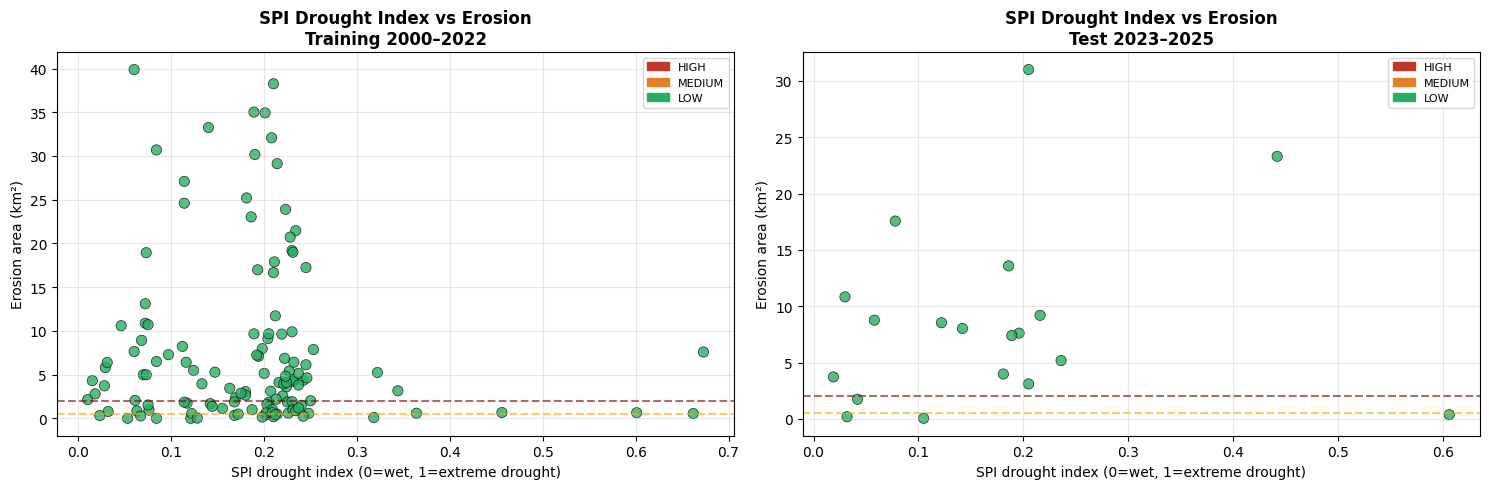

In [ ]:
fig,axes=plt.subplots(1,2,figsize=(15,5))

for ax,df2,sn in [(axes[0],df_train,'Training 2000–2022'),
                   (axes[1],df_test,'Test 2023–2025')]:
    if df2 is None or len(df2)==0:
        ax.text(0.5,0.5,'No data',ha='center',va='center',transform=ax.transAxes)
        continue
    cols=[RISK_COLOR.get(r,'gray') for r in df2['vlm_risk']]
    sc=ax.scatter(df2['drought_idx'],df2['erosion_km2'],
                  c=cols,s=55,edgecolor='k',linewidth=0.5,alpha=0.8)
    ax.axhline(RISK_HIGH_KM2,  ls='--',color='darkred',alpha=0.6,label=f'HIGH ({RISK_HIGH_KM2}km²)')
    ax.axhline(RISK_MEDIUM_KM2,ls='--',color='orange', alpha=0.6,label=f'MEDIUM ({RISK_MEDIUM_KM2}km²)')
    ax.set_title(f'SPI Drought Index vs Erosion\n{sn}',fontweight='bold')
    ax.set_xlabel('SPI drought index (0=wet, 1=extreme drought)')
    ax.set_ylabel('Erosion area (km²)')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    patches=[mpatches.Patch(color=v,label=k)
             for k,v in RISK_COLOR.items() if k!='?']
    ax.legend(handles=patches,fontsize=8,loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(OUT_PATH,'fig_drought_vs_erosion.png'),dpi=150,bbox_inches='tight')
plt.show()

---
## PART 12 — Paper-Ready Results Table

In [ ]:
if all_m:
    paper=summary[[
        'split','n_pairs',
        'high_prec','high_rec','high_f1',
        'med_prec', 'med_rec', 'med_f1',
        'low_prec', 'low_rec', 'low_f1',
        'macro_f1','kappa','accuracy','parse_rate'
    ]].copy()
    paper.columns=[
        'Split','N pairs',
        'Prec(H)','Rec(H)','F1(H)',
        'Prec(M)','Rec(M)','F1(M)',
        'Prec(L)','Rec(L)','F1(L)',
        'Macro F1','Kappa','Accuracy','Parse Rate'
    ]
    print('\n' + '='*80)
    print('  TABLE — PADMA RIVER EROSION DETECTION: VLM VALIDATION RESULTS')
    print('  (H=HIGH risk, M=MEDIUM risk, L=LOW risk)')
    print('='*80)
    print(paper.to_string(index=False,float_format='{:.3f}'.format))
    print()
    print('Reference labels: Rule-based pseudo-ground-truth')
    print('  HIGH   = erosion_km² > 2.0 OR channel_shift > 300 m')
    print('  MEDIUM = erosion_km² 0.5–2.0')
    print('  LOW    = erosion_km² < 0.5')
    print('Source: Islam et al. (2021) Remote Sensing — Padma monthly erosion rates')
    print()
    kinterp=lambda k: ('Slight' if k<0.2 else 'Fair' if k<0.4 else
                       'Moderate' if k<0.6 else 'Substantial' if k<0.8 else 'Almost Perfect')
    for _,row in paper.iterrows():
        print(f"  {row['Split']}: Kappa={row['Kappa']:.3f} → {kinterp(row['Kappa'])} agreement")

    if len(loyo_df)>0:
        print()
        print(f'LOYO-CV (Training Set):')
        print(f'  Mean accuracy : {loyo_df["vlm_acc"].mean():.3f} ± {loyo_df["vlm_acc"].std():.3f}')
        print(f'  Mean Kappa    : {loyo_df["kappa"].mean():.3f} ± {loyo_df["kappa"].std():.3f}')
        print(f'  Mean HIGH F1  : {loyo_df["high_f1"].mean():.3f}')

    paper.to_csv(os.path.join(OUT_PATH,'paper_results_table.csv'),index=False)
    if len(loyo_df)>0:
        loyo_df.to_csv(os.path.join(OUT_PATH,'paper_loyo_cv_table.csv'),index=False)
    print(f'\n✅ Tables saved to: {OUT_PATH}')


  TABLE — PADMA RIVER EROSION DETECTION: VLM VALIDATION RESULTS
  (H=HIGH risk, M=MEDIUM risk, L=LOW risk)
          Split  N pairs  Prec(H)  Rec(H)  F1(H)  Prec(M)  Rec(M)  F1(M)  Prec(L)  Rec(L)  F1(L)  Macro F1  Kappa  Accuracy  Parse Rate
TRAIN_2000_2022      127    0.000   0.000  0.000    0.000   0.000  0.000    0.063   1.000  0.118     0.040  0.000     0.063       1.000
 TEST_2023_2025       19    0.000   0.000  0.000    0.000   0.000  0.000    0.053   1.000  0.100     0.033  0.000     0.053       1.000

Reference labels: Rule-based pseudo-ground-truth
  HIGH   = erosion_km² > 2.0 OR channel_shift > 300 m
  MEDIUM = erosion_km² 0.5–2.0
  LOW    = erosion_km² < 0.5
Source: Islam et al. (2021) Remote Sensing — Padma monthly erosion rates

  TRAIN_2000_2022: Kappa=0.000 → Slight agreement
  TEST_2023_2025: Kappa=0.000 → Slight agreement

LOYO-CV (Training Set):
  Mean accuracy : 0.065 ± 0.128
  Mean Kappa    : 0.000 ± 0.000
  Mean HIGH F1  : 0.000

✅ Tables saved to: /content/drive

---
## PART 13 — Final Output Index

In [ ]:
print('='*70)
print(' PADMA EROSION DETECTION v7 — COMPLETE')
print('='*70)
print()
print('SPLITS:')
for nm,df2 in [('Train 2000–2022',df_train),('Test 2023–2025',df_test)]:
    if df2 is not None and len(df2)>0:
        ok=(df2['parse_strat']!='rule_based_fallback').sum()
        print(f'  {nm:25s}: {len(df2):3d} pairs | VLM parse {ok}/{len(df2)} '
              f'({ok/len(df2)*100:.1f}%)')
print()
print('OUTPUT FILES:')
FILE_DESC={
    'paper_results_table.csv'    : '← PUT THIS IN YOUR PAPER (Table 1)',
    'paper_loyo_cv_table.csv'    : '← PUT THIS IN YOUR PAPER (Table 2)',
    'fig_train_vs_test_main.png' : '← MAIN FIGURE (Train vs Test)',
    'fig_cm_TRAIN_2000_2022.png' : '← Confusion matrix — training set',
    'fig_cm_TEST_2023_2025.png'  : '← Confusion matrix — test set',
    'fig_prf1_TRAIN_2000_2022.png':'← Prec/Recall/F1 — training',
    'fig_prf1_TEST_2023_2025.png' :'← Prec/Recall/F1 — test',
    'fig_loyo_cv.png'            : '← LOYO cross-validation',
    'fig_timeline_TRAIN_2000_2022.png':'← Temporal erosion timeline — train',
    'fig_timeline_TEST_2023_2025.png' :'← Temporal erosion timeline — test',
    'fig_seasonal.png'           : '← Seasonal erosion patterns',
    'fig_drought_vs_erosion.png' : '← SPI drought vs erosion scatter',
    'fig_calib_TRAIN_2000_2022.png':'← Confidence calibration — train',
    'fig_calib_TEST_2023_2025.png' :'← Confidence calibration — test',
    'sanity_TRAIN_SET.png'       : '← Water mask visual QA — train',
    'sanity_TEST_SET.png'        : '← Water mask visual QA — test',
}
for f in sorted(os.listdir(OUT_PATH)):
    p=os.path.join(OUT_PATH,f)
    desc=FILE_DESC.get(f,'')
    print(f'  {f:50s} {os.path.getsize(p)/1024:7.1f} KB  {desc}')
print('='*70)

 PADMA EROSION DETECTION v7 — COMPLETE

SPLITS:
  Train 2000–2022          : 127 pairs | VLM parse 127/127 (100.0%)
  Test 2023–2025           :  19 pairs | VLM parse 19/19 (100.0%)

OUTPUT FILES:
  ckpt_TEST_2023_2025_20260504_0308.csv                 10.6 KB  
  ckpt_TRAIN_2000_2022_20260504_0244.csv               115.6 KB  
  fig_calib_TEST_2023_2025.png                          40.5 KB  ← Confidence calibration — test
  fig_calib_TRAIN_2000_2022.png                         40.6 KB  ← Confidence calibration — train
  fig_cm_TEST_2023_2025.png                             37.9 KB  ← Confusion matrix — test set
  fig_cm_TRAIN_2000_2022.png                            39.7 KB  ← Confusion matrix — training set
  fig_drought_vs_erosion.png                           133.3 KB  ← SPI drought vs erosion scatter
  fig_loyo_cv.png                                       77.5 KB  ← LOYO cross-validation
  fig_prf1_TEST_2023_2025.png                           39.5 KB  ← Prec/Recall/F1 — test
  fig_